# ROM for SWE using the EA-POD-NN method

## The 2-D SWEs system:

$$\begin{equation} \label{eq:SWe}
(\mathcal{M}_{\mu}) \left\{ \begin{array}{lll}
\partial_{t}h+div(\mathbf{q}) & =  0 & \textrm{ in } \Omega~ \times ~]0,T]\\
\partial_{t}\mathbf{q}+div\left(\dfrac{\mathbf{q}\otimes\mathbf{q}}{h}+g\dfrac{h^{2}}{2}Id\right) & =  S_g(\mu; h) + S_f(\mu; h, \mathbf{q}) & \textrm{ in } \Omega~ \times ~]0,T] \\
\mbox{Plus Initial Conditions, } & \mbox{ plus Boundary Conditions (B.C.)($\mu$)}& 
\end{array}\right..
\end{equation} $$

## The parameter space $P_s$

### Source librairies

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import subprocess

### Class to generate the hydrographs and input parameter for the EA-POD-NN method

In [2]:
# Define the class to generate the triangular hydrographs and correspond input parameters for the EA-POD-NN method
class HydrographGenerator:
    
    # Initialization
    def __init__(self, n=48, q1_max=7.0, q2_max=2.0, step=172800. / 48):
        
        self.n = n
        self.Q1 = np.zeros(n)
        self.Q2 = np.zeros(n)
        self.Q1[:13] = q1_max
        self.Q2[:13] = q2_max
        self.qmin1 = np.min(self.Q1)
        self.qmin2 = np.min(self.Q2)
        self.qmax1 = np.max(self.Q1)
        self.qmax2 = np.max(self.Q2)
        self.step = step
        self.Time = np.arange(start=3600, stop=172800. + 3600., step=step)
        self.Time_simu = np.arange(start=0., stop=216000. + 10800., step=10800.)
        self.Time_simu = self.Time_simu[12:]
        np.save('Time_simu', self.Time_simu)
        
    # Function to construct triangular hydrographs
    def f(self, t, tmax, qmax, tmente, qmin, tdescente):
        
        if tmente <= t <= tmax:
            a = (qmax - qmin) / (tmax - tmente)
        elif tmax <= t <= tdescente:
            a = (qmin - qmax) / (tdescente - tmax)
        else:
            return 0  # Assuming 0 if t is outside the specified ranges
        b = qmax - a * tmax
        return a * t + b

    # Function to construct the parameter space  
    def generate_parameter_space(self, mu1_range, mu2_range, mu3_range, mu4_range, constraint):
        
        parameter_space = []

        for mu1 in mu1_range:
            for mu3 in mu3_range:
                if abs(mu1 - mu3) / abs(mu1) <= constraint:
                    for mu2 in mu2_range:
                        for mu4 in mu4_range:
                            parameter_space.append((mu1, mu2, mu3, mu4))

        return parameter_space
    
    # Function to check if the constraint is satisfied or not
    def check_constraint(self, param, constraint):
        
        if abs(param[0] - param[2]) / abs(param[0]) <= constraint:
            
            print('The point is good with constraint:', abs(param[0] - param[2]) / abs(param[0]))
        else:
            
            print('The point is not good because the constraint is:',
                  abs(param[0] - param[2]) / abs(param[0]))
            
    # Function to plot the parameter space
    def plot_parameter_space(self, echantillons, param, tmontee1, tmontee2):
        
        Tmax1 = echantillons[:, 0] - tmontee1
        Tmax2 = echantillons[:, 2] - tmontee2
        Qmax1 = echantillons[:, 1]
        Qmax2 = echantillons[:, 3]

        #Tmax1 = Tmax1 / 3600.
        #Tmax2 = Tmax2 / 3600.

        fig1, ax1 = plt.subplots()
        ax1.scatter(Tmax1, Tmax2, s=5, color='b', marker='o')
        ax1.set_xlabel('$t_{peak,1}$ ($h$)', fontsize=14)
        ax1.set_ylabel('$t_{peak,2}$ ($h$)', fontsize=12)
        #ax1.scatter(param[0] / 3600., param[2] / 3600., color='red', marker='o')
        #fig1.savefig('The_parameter_space_t1vst2_phased.png')

        fig2, ax2 = plt.subplots()
        ax2.scatter(Tmax1, Qmax1, s=5, color='b', marker='o')
        ax2.set_xlabel('$t_{peak,1}$ ($h$)', fontsize=14)
        ax2.set_ylabel('Discharge $Q_{max,1}$ ($m^3.s^{-1}$)', fontsize=12)
        #ax2.scatter(param[0] / 3600., param[1], color='red', marker='o')
        #fig2.savefig('The_parameter_space_t1vsQ1_phased.png')

        fig3, ax3 = plt.subplots()
        ax3.scatter(Tmax2, Qmax2, s=5, color='b', marker='o')
        ax3.set_xlabel('$t_{peak,1}$ ($h$)', fontsize=14)
        ax3.set_ylabel('Discharge $Q_{max,2}$ ($m^3.s^{-1}$)', fontsize=12)
        #ax3.scatter(param[2] / 3600., param[3], color='red', marker='o')
        #fig3.savefig('The_parameter_space_t2vsQ2_phased.png')
        plt.show()
     
    # Function to generate the triangular hydrographs and corresponding numpy vectors for the offline phase
    def generate_hydrographs(self, echantillons, tmontee1, tmontee2):
        
        Qin1 = np.zeros((self.n, len(echantillons)))
        Qin2 = np.zeros((self.n, len(echantillons)))
        
        for m in range(len(echantillons)):
            tmax1 = echantillons[m, 0] 
            tmax2 = echantillons[m, 2] 
            tdescente1 = 2 * tmax1 - tmontee1
            tdescente2 = 2 * tmax2 - tmontee2
            Q1 = np.full(self.n, 7.0)
            Q2 = np.full(self.n, 2.0)
            qmax1 = echantillons[m, 1]
            qmax2 = echantillons[m, 3]

            for i in range(self.n):
                if tmontee1 <= self.Time[i] <= tdescente1:
                    Q1[i] = self.f(self.Time[i], tmax1, qmax1, tmontee1, self.qmin1, tdescente1)
                if tmontee2 <= self.Time[i] <= tdescente2:
                    Q2[i] = self.f(self.Time[i], tmax2, qmax2, tmontee2, self.qmin2, tdescente2)
                    
            plt.plot(self.Time, Q1, label='Q1 real')
            plt.plot(self.Time, Q2, label='Q2 real')
            plt.title('The inflow for Qmax1=' + str(qmax1) + '$m^3.s^{-1}$ and Qmax2=' + str(qmax2) + ' (s)')
            plt.xlabel(r'Time ($s$)')
            plt.ylabel(r'Discharge ($m^3.s^{-1}$)')
            plt.legend()
            plt.show()    

            Qin1[:, m] = Q1
            Qin2[:, m] = Q2
            np.save('Qin1',Qin1);np.save('Qin2',Qin2)

        return Qin1, Qin2
    
    # Function to generate the triangular hydrograph for the online phase
    def generate_hydrograph_online(self, Q1, Q2, Time, tmontee, param):
        
        Q1 = Q1 + 7.; Q2 = Q2 + 2. 
        tmax1 = param[0] + tmontee; tmax2 = param[2] + tmontee
        qmax1 = param[1]; qmax2 = param[3]
        tdescente1 = 2 * tmax1 - tmontee; tdescente2 = 2 * tmax2 - tmontee
        for i in range(len(Q1)):
            if (Time[i] >= tmontee and Time[i] <= tdescente1):
                Q1[i] = self.f(Time[i], tmax1, qmax1, tmontee, self.qmin1, tdescente1)
            if (Time[i] >= tmontee and Time[i] <= tdescente2):
                Q2[i] = self.f(Time[i], tmax2, qmax2, tmontee, self.qmin2, tdescente2)

        plt.plot(Time, Q1, label='Q1 real')
        plt.plot(Time, Q2, label='Q2 real')
        plt.title('The inflow for Qmax1=' + str(qmax1) + '$m^3.s^{-1}$ and Qmax2=' + str(qmax2) + ' (s)')
        plt.xlabel(r'Time ($s$)')
        plt.ylabel(r'Discharge ($m^3.s^{-1}$)')
        plt.legend()
        plt.show()
        
        nameHydro         ='hydrograph.txt'
        linspace=len(Time)
        print("Number of elements in Time:", len(Time))
        print("Number of elements in Flow1:", len(Q1))
        file=open(nameHydro,'w+')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write(str((3))+'\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write(str((linspace))+'\n')
        for i in range(linspace):
            file.write(str(Time[i]) + ' ' +str(0.0)+'\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write(str((linspace))+'\n')
        for i in range(linspace):
            file.write(str(Time[i]) + ' ' +str(Q1[i])+'\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write('#comment\n')
        file.write(str((linspace))+'\n')
        for i in range(linspace):
            file.write(str(Time[i]) + ' ' +str(Q2[i])+'\n')
        file.write('#comment\n')
        file.close()
        
        np.save('Q_1', Q1)
        np.save('Q_2', Q2)
        subprocess.run(['cp', nameHydro, '/home-local/allabou/Bureau/dasshydro-main/cases/dev_case/Aude/built_bin/'])
    
    # Function to construct the EA-POD-NN input parameters
    def generate_pod_nn_parameters(self, echantillons,tmontee1,tmontee2):
        
        POD_NN_Parameters = []

        for j in range(len(echantillons)):
            for k in range(len(self.Time_simu)):
                tmax1 = echantillons[j, 0] + tmontee1
                qmax1 = echantillons[j, 1]
                tmax2 = echantillons[j, 2] + tmontee2
                qmax2 = echantillons[j, 3]
                time_simu_k = self.Time_simu[k]

                POD_NN_Parameters.append([tmax1 - tmontee1, qmax1, tmax2 - tmontee2, qmax2, time_simu_k])
        POD_NN_Parameters = np.array(POD_NN_Parameters)
        np.save('POD_NN_Parameters',POD_NN_Parameters)

        return POD_NN_Parameters

## Computation of the snapshots using DassFlow software in parallel

### Source librairies

In [3]:
import os
import shutil
import multiprocessing
from multiprocessing import Manager, Pool
import logging
import numpy as np
import dassflow2d as df2d

### Class for snapshots computation

In [4]:
# Class to run the simulation in parallel
class DassFlowRunner:
    
    def __init__(self, dassflow_dir, code_dir, save_dir):
        
        self.dassflow_dir = dassflow_dir
        self.code_dir = code_dir
        self.save_dir = save_dir
        self.Qin1 = None
        self.Qin2 = None

    # Function to set the hydrographs numpy vectors
    def set_qin_data(self, Qin1, Qin2):
        
        self.Qin1 = Qin1
        self.Qin2 = Qin2

    # Function to copy the test case files to bin directory    
    def copy_case_files(self, bin_dir):
        
        os.system(f"cp -r {self.dassflow_dir}/cases/dev_case/Aude/built_bin/* {bin_dir}")

    # Function to initialize the DassFlow model
    def initialize_model(self, bin_dir):
        
        my_model = df2d.dassflowmodel(bin_dir=bin_dir, hdf5_path=f"{bin_dir}/res/simu.hdf5", run_type="direct", clean=True)
        my_model.init_all()
        return my_model

    # Function for one run of simulation
    def one_run(self, dassflow_dir, bin_dir, run_type, ts, dtw, qin1, qin2, id_experiment, save_dir, result_queue):
        
        os.system(f"cp -r {dassflow_dir}/cases/dev_case/Aude/built_bin/* {bin_dir}")
        my_model = df2d.dassflowmodel(bin_dir=bin_dir, hdf5_path=f"{bin_dir}/res/simu.hdf5", run_type=run_type, clean=True)
        my_model.init_all()
        my_bc = df2d.wrapping.m_model.get_bc()
        my_bc.hyd[1].q = qin1[:, id_experiment]
        my_bc.hyd[2].q = qin2[:, id_experiment]
        my_model.run()
        my_model.save_all()
        if not os.path.exists(f"{save_dir}/{id_experiment}"):
            os.mkdir(f"{save_dir}/{id_experiment}")
        os.system(f"cp {bin_dir}/res/simu.hdf5 {save_dir}/{id_experiment}")
        df2d.wrapping.call_model.clean_model(my_model.kernel)

    # Function to run simulation in parallel,the data is divided for each processor
    def parallel_run(self, start_index, end_index, dassflow_dir, bin_dir, run_type, ts, dtw, save_dir, result_queue):
        
        for id_experiment in range(start_index, end_index):
            
            self.one_run(dassflow_dir, bin_dir, run_type, ts, dtw, self.Qin1, self.Qin2, id_experiment, save_dir, result_queue)

    # Function  to run the simulation in parallel on each processor
    def run_simulations(self, num_processes, run_type, ts, dtw):
        
        if self.Qin1 is None or self.Qin2 is None:
            raise ValueError("Qin1 and Qin2 must be set before running simulations.")

        manager = Manager()
        result_queue = manager.Queue()
        experiments_per_process = len(self.Qin1[0, :]) // num_processes
        pool = Pool()
        processes = []

        for i in range(num_processes):
            bin_dir = os.path.join(self.code_dir, f"bin_dir_{i}")
            if not os.path.exists(bin_dir):
                os.makedirs(bin_dir)
            start_index = i * experiments_per_process
            end_index = start_index + experiments_per_process if i < num_processes - 1 else len(self.Qin1[0, :])
            process = pool.apply_async(self.parallel_run, args=(start_index, end_index, self.dassflow_dir, bin_dir, run_type, ts, dtw, self.save_dir, result_queue))
            processes.append(process)

        while not result_queue.empty():
            file_path = result_queue.get()
            shutil.copy(file_path, self.save_dir)

        for process in processes:
            process.get()

        pool.close()
        pool.join()

## Reduced Basis (RB) matrices $\mathbf{B}_{rb}$ and  $\mathbf{B}_{er}$  computation

### Computation of the RB matrix $\mathbf{B}_{rb}$

#### Source librairies

In [5]:
import numpy as np
import os
import h5py
import numpy.linalg as npl
import scipy
import matplotlib.pyplot as plt
from math import atan
from numpy.linalg import eig
import pandas as pd
from scipy.linalg import eigh
import time
from datetime import datetime

#### Class to compute the RB matrix $\mathbf{B}_{rb}$ 

In [6]:
# Class to compute the RB matrix Brb 
class PODProcessor:
    
    def __init__(self, M=2, Nt=500, Nh=7267, epsilon_POD=None, data_directory=None):
        self.M = M
        self.Nt = Nt
        self.Nh = Nh
        self.step = 500
        self.Ns = Nt * M
        self.H = np.zeros(Nh)
        self.U = np.zeros(Nh)
        self.V = np.zeros(Nh)
        self.FROUD = np.zeros(Nh)
        self.epsilon_POD = epsilon_POD
        self.Snapshots = None
        self.Eigen_val = None
        self.Eigen_vec = None
        self.Brb = None
        self.s_eigen = None  # Nouvel attribut pour stocker s_eigen
        self.data_directory = data_directory

    # Function to read the data files where the simulation were stored
    def read_data_files(self):
        
        for i in range(self.M):
            # Read the hdf5 files
            f = h5py.File(os.path.join(self.data_directory, str(i), 'simu.hdf5'), 'r')

            # Access a specific group
            group = f['output']

            # Access a specific data set within the group
            dataset = group['result']

            # Reading data from a numpy table
            h = dataset['h']
            u = dataset['u']
            v = dataset['v']

            # Get the water depth
            h = np.array(h)
            h = h[:, 12:]
            #print('h shape is ',h.shape)
            
            # Get the x direction velocity
            u = np.array(u)
            u = u[:, 12:]

            # Get the y direction velocity
            v = np.array(v)
            v = v[:, 12:]

            # Compute the Froude number
            #g = 10.
            #Froud_nbr = np.sqrt(u**2 + v**2) / np.sqrt(g * h)

            # Concatenate the output variables into matrices
            self.U = np.c_[self.U, u]
            self.V = np.c_[self.V, v]
            self.H = np.c_[self.H, h]
            #self.FROUD = np.c_[self.FROUD, Froud_nbr]

        # Save the data in numpy files
        self.H = self.H[:, 1:]
        self.U = self.U[:, 1:]
        self.V = self.V[:, 1:]
        self.Snapshots = np.concatenate((self.H, self.U, self.V))
        self.Snapshots = self.Snapshots[:, 1:]
        np.save('Snapshots', self.Snapshots)
        #print('snapshots shape is ',self.Snapshots.shape)
        return self.Snapshots


    # Function to compute the eigen element of the correlation matrix
    def compute_eigenvalues(self):
        
        C = np.dot(self.Snapshots.transpose(), self.Snapshots) 
        print("cond of C=", npl.cond(C, 2))
        start_time = datetime.now()
        self.Eigen_val, self.Eigen_vec = np.linalg.eigh(C)
        Xi = np.zeros((len(self.Snapshots),len(self.Eigen_vec)))
        for i in range(len(self.Eigen_vec)):
            Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(self.Snapshots,self.Eigen_vec[:,i])
        self.Eigen_vec = Xi
        self.normalize_eigenvalues()  
        
        end_time = datetime.now()
        print('Duration: {}'.format(end_time - start_time))
        a = np.argsort(-self.Eigen_val)
        self.Eigen_val = self.Eigen_val[a]
        self.Eigen_vec = self.Eigen_vec[:, a]
        np.save('Eigen_values', self.Eigen_val)


    # Function to plot the eigenvalues in the descending order 
    def plot_eigenvalues(self):
        
        a = np.argsort(-self.Eigen_val)
        self.Eigen_val = self.Eigen_val[a]
        Eigen_vec = self.Eigen_vec[:, a]
        
        Eigen_val_normalized = self.normalize_eigenvalues()
        
        Decay = np.arange(len(self.Eigen_val))
        fig = plt.figure(figsize=(12, 8))
        ax = fig.gca()
        ax.plot(Decay, Eigen_val_normalized, label='Normalized eigenvalues', color='r')
        ax.set_xticks(Decay)
        ax.set_xticklabels([r'$\lambda_{%i}$' % (i + 1) for i in Decay], fontsize=20)
        plt.xscale("log")
        plt.yscale("log")
        width = 0.5
        p = plt.bar(Decay, Eigen_val_normalized, width, color='b')
        plt.legend(fontsize=16)
        ax.legend(fontsize=16)
        ax.yaxis.set_tick_params(labelsize=16)
        plt.show()
     
    # Function to normalize the eigenvalues
    def normalize_eigenvalues(self):
        
        if self.s_eigen is None:
            self.s_eigen = np.sum(self.Eigen_val)
            print('s_eigen =', self.s_eigen)
        Eigen_val_normalized = (self.Eigen_val) / self.s_eigen
        return Eigen_val_normalized

    # Function to compute the reduced dimension Nrb
    def compute_number_of_modes(self, epsilon_POD):
        
        Nrb = self.energy_number(epsilon_POD)
        print('This corresponds to Nrb = ', Nrb)
        return Nrb
    
    # Function to determine the reduced dimension Nrb using a tolerance epsilon_POD
    def energy_number(self, epsilon_POD):
        
        Eigen_val_normalized = self.normalize_eigenvalues()
        s1 = np.sum(Eigen_val_normalized)
        s = 0.
        index_min = 0
        for i in range(len(Eigen_val_normalized)):
            if s < s1 * (1 - epsilon_POD):
                s += Eigen_val_normalized[i]
                index_min += 1
        return index_min

    # Function to trancate the first Nrb POD Modes that are stored in RB matrix Brb
    def truncate_reduced_basis(self, Nrb):
        
        if self.Brb is None:
            self.Brb = self.Eigen_vec[:, 0:Nrb]
            print("Brb shape is", self.Brb.shape)
            np.save('Brb', self.Brb)
        return self.Brb

    # Function to compute the error estimation satified by the POD method
    def compute_error_estimation(self):
        
        Uh = np.zeros(len(self.Snapshots))
        S = 0.

        for m in range(len(self.Snapshots[0])):
            Uh = self.Snapshots[:, m]
            Urb = np.dot(self.Brb, np.dot(self.Brb.transpose(), Uh))
            Diff = Uh - Urb
            S += np.dot(Diff.transpose(), Diff)

        Discarded_eigenvalues = np.sum(self.Eigen_val[len(self.Brb):])
        print("The error estimation by POD method is", abs(S - Discarded_eigenvalues) / abs(self.s_eigen))

### Computation of the RB matrix $\mathbf{B}_{er}$

#### Source librairies

In [7]:
import numpy as np
import os
import h5py
import numpy.linalg as npl
import scipy
import matplotlib.pyplot as plt
from math import atan
from numpy.linalg import eig
import pandas as pd
from scipy.linalg import eigh
import time
from datetime import datetime
from POD_Basis import PODProcessor

#### Class to compute the RB matrix $\mathbf{B}_{er}$ 

In [8]:
# Class to compute the RB matrix Ber for error matrix
class PODProcessor_error: 
    
    def __init__(self,epsilon_er=None):
        self.epsilon_er = epsilon_er
        self.Snapshots = None
        self.Eigen_val = None
        self.Eigen_vec = None
        self.Ber = None
        self.s_eigen = None

    # Function to compute the eigenvalues of the correlation matrix for error matrix Er
    def compute_eigenvalues_er(self,Snapshots,Nrb,Brb):
        
        print('Nrb is equal to',Nrb)
        print('Brb is of shape',Brb.shape)
        Er = Snapshots - np.dot(Brb, np.dot(Brb.transpose(), Snapshots))
        C = np.dot(Er.transpose(), Er)
        print("cond of C=", npl.cond(C, 2))
        start_time = datetime.now()
        self.Eigen_val, self.Eigen_vec = np.linalg.eigh(C)
        a = np.argsort(-self.Eigen_val)
        self.Eigen_val = self.Eigen_val[a]
        self.Eigen_vec = self.Eigen_vec[:, a]
        Xi = np.zeros((len(Snapshots),len(self.Eigen_vec)))
        for i in range(len(self.Eigen_vec)):
            Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(Snapshots,self.Eigen_vec[:,i])
        self.Eigen_vec = Xi
        end_time = datetime.now()
        print('Duration: {}'.format(end_time - start_time))
        np.save('Eigen_values_error', self.Eigen_val)
        np.save('Er',Er)

    # Function to plot the eigenvalues 
    def plot_eigenvalues_er(self):
        
        a = np.argsort(-self.Eigen_val)
        self.Eigen_val = self.Eigen_val[a]
        Eigen_vec = self.Eigen_vec[:, a]

        Eigen_val_normalized = self.normalize_eigenvalues_er()

        Decay = np.arange(len(self.Eigen_val))
        fig = plt.figure(figsize=(12, 8))
        ax = fig.gca()
        ax.plot(Decay, Eigen_val_normalized, label='Normalized errors eigenvalues', color='r')
        ax.set_xticks(Decay)
        ax.set_xticklabels([r'$\lambda_{%i}$' % (i + 1) for i in Decay], fontsize=20)
        plt.xscale("log")
        plt.yscale("log")
        width = 0.5
        p = plt.bar(Decay, Eigen_val_normalized, width, color='b')
        plt.legend(fontsize=16)
        ax.legend(fontsize=16)
        ax.yaxis.set_tick_params(labelsize=16)
        plt.show()
        
    # Function to normalize the eigenvalues   
    def normalize_eigenvalues_er(self):
        
        if self.s_eigen is None:
            self.s_eigen = np.sum(self.Eigen_val)
            print('s_eigen =', self.s_eigen)
        Eigen_val_normalized = (self.Eigen_val) / self.s_eigen
        return Eigen_val_normalized

     # Function to compute the reduced dimension Ner
    def compute_number_of_modes_er(self, epsilon_er):
        
        Ner = self.energy_number_er(epsilon_er)
        print('This corresponds to Ner = ', Ner)
        return Ner
    
    # Function to determine the reduced dimension Ner using a tolerance epsilon_er
    def energy_number_er(self, epsilon_er):
        
        Eigen_val_normalized = self.normalize_eigenvalues_er()
        s1 = np.sum(Eigen_val_normalized)
        s = 0.
        index_min = 0
        for i in range(len(Eigen_val_normalized)):
            if s < s1 * (1 - epsilon_er):
                s += Eigen_val_normalized[i]
                index_min += 1
        return index_min

     # Function to trancate the first Ner POD Modes that are stored in RB matrix Ber
    def truncate_reduced_basis_er(self, Ner):
        
        if self.Ber is None:
            self.Ber = self.Eigen_vec[:, 0:Ner]
            print("Ber shape is", self.Ber.shape)
            np.save('Ber', self.Ber)
        return self.Ber

    # Function to compute the error estimation satified by the POD method
    def compute_error_estimation_er(self,Snapshots):
        
        Uh = np.zeros(len(Snapshots.transpose()))
        S = 0.

        for m in range(len(Snapshots.transpose()[0])):
            Uh = Snapshots.transpose()[:, m]
            Urb = np.dot(self.Ber, np.dot(self.Ber.transpose(), Uh))
            Diff = Uh - Urb
            S += np.dot(Diff.transpose(), Diff)

        Discarded_eigenvalues = np.sum(self.Eigen_val[len(self.Ber):])
        print("The error estimation by POD method for error matrix is", abs(S - Discarded_eigenvalues) / abs(self.s_eigen))

## The EA-POD-NN reduction method

### The offline (training) phase

#### Source librairies

In [9]:
import tensorflow as tf
import tensorflow.keras as k
from tensorflow.keras.regularizers import l2 
from tensorflow.keras.datasets import mnist
import tensorflow.keras.preprocessing.image as kpi
import tensorflow.keras.models as km
import tensorflow.keras.layers as kl
import tensorflow.keras.losses as kloss
import tensorflow.keras.regularizers as kr
import tensorflow.keras.backend as K
import tensorflow.keras.utils as ku
from tensorflow.keras import callbacks
import scipy as sc
import numpy as np
import numpy.linalg as npl
import matplotlib.pyplot as plt
import sys,os
import random 
import pandas as pd
import sklearn.utils
import time
from sklearn.preprocessing import MinMaxScaler
# Verbosity
fit_verbosity = 1

2024-02-15 15:46:21.064827: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-15 15:46:21.089569: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-15 15:46:21.089590: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-15 15:46:21.090355: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-15 15:46:21.094605: I tensorflow/core/platform/cpu_feature_guar

#### Class to train the Neural Networks (NNs) 

In [10]:
# Class to train the NNs 
class POD_NN_METHOD:
    
    def __init__(self,input_dim, Nrb, Ner, Neurons, Neurons_er, epochs, batch_size, lr, alpha, alpha1):
        self.input_dim = input_dim
        self.Nrb = Nrb
        self.Ner = Ner
        self.Neurons = Neurons
        self.Neurons_er = Neurons_er
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.alpha = alpha
        self.alpha1 = alpha1
        self.model = self.build_model(Neurons=self.Neurons)
        self.model_er = self.build_model_er(Neurons_er=self.Neurons_er)
        self.max_P = None
        self.min_P = None
        self.Urb_POD_max1 = None
        self.Urb_POD_min1 = None
        self.Brb = None
        self.Ber = None
        self.Er = None
        self.scaler = MinMaxScaler()
        
        # Check for GPU and set memory growth
        gpus = tf.config.experimental.list_physical_devices('GPU')
        if gpus:
            # Vous avez au moins un GPU
            print("Using GPU:", gpus[0])
            try:
                # Limit TensorFlow to use the first GPU
                tf.config.experimental.set_visible_devices(gpus[0], 'GPU')
                
                # Specify dynamic memory usage for the GPU
                for gpu in gpus:
                    tf.config.experimental.set_memory_growth(gpu, True)
                    
                print("Using GPU:", gpus[0])
            except RuntimeError as e:
                print(e)
        else:
            # No GPU, TensorFlow will use the CPU
            print("No GPU detected. Using CPU.")


    # Function to build the first NN (to learn the reduced coefficients of snapshots)
    def build_model(self, Neurons):
        
        model = tf.keras.Sequential([
            tf.keras.layers.Dense(Neurons, input_dim = self.input_dim, activation='relu'),  # Updated input_dim to 5
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(Neurons, activation = 'relu'),
            tf.keras.layers.Dense(self.Nrb)
        ])
        model.summary()
        return model
    
    # Function to build the second NN (to learn the reduced coefficients of errors)
    def build_model_er(self, Neurons_er):
        
        model = tf.keras.Sequential([
            tf.keras.layers.Dense(Neurons_er, input_dim = self.input_dim, activation='relu'),  # Updated input_dim to 5
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(Neurons_er, activation = 'relu'),
            tf.keras.layers.Dense(self.Ner)
        ])
        model.summary()
        return model
    
    # Function to normalize the data (this put the data value in [0,1])
    def normalize_data(self, data):
        
        data_max = np.max(data)
        data_min = np.min(data)
        normalized_data = (data - data_min) / (data_max - data_min)
        return normalized_data, data_max, data_min
    
    # Function to normalize the data (this put the data value in [0,1])
    def scaling(self, S, S_max, S_min):
        
        S[...] = (S - S_min) / (S_max - S_min)
    
    # Function to return to original data 
    def inverse_normalize_data(normalized_data,data_min,data_max):
        
        """
        Inverse normalize the input data that was previously normalized using Min-Max scaling.
           
        Returns:
        - original_data: The data after inverse normalization.
        """
        original_data = normalized_data * (data_max - data_min) + data_min
        return original_data
    
    # Function to return to original data 
    def inverse_scaling(self, S, S_max, S_min):
        
        S[...] = (S_max - S_min) * S + S_min

    # Function to load the data 
    def load_data(self):
        
        # Load your data here (S, Brb, P, etc.)
        self.S = np.load('Snapshots.npy')
        self.Brb = np.load('Brb.npy')
        self.P = np.load('POD_NN_Parameters.npy')
        self.P = self.P[:269,:]
        self.Er = np.load('Er.npy')
        self.Ber = np.load('Ber.npy')
        
        #
        # Compute the reduced data
        self.Urb_POD = np.dot(self.Brb.transpose(), self.S).transpose()
        self.Urb_POD_er = np.dot(self.Ber.transpose(), self.Er).transpose()
        
        # Or sequentialy
        
        print("len Urb_POD_train=", self.Urb_POD.shape)
        print("len Urb_POD_train_er=", self.Urb_POD_er.shape)
        print("len P=", self.P.shape)

    # Function to split the data into train, test and validation data
    def split_data(self):
        
        N = len(self.P)
        alpha = self.alpha
        alpha1 = self.alpha1
        N_tr = int(N * (1 - (alpha + alpha1)))
        N_test = int(N * (1 - alpha1))
        
        # Compute the train data
        self.Urb_POD_train = self.Urb_POD[:N_tr, :]
        self.Urb_POD_train_er = self.Urb_POD_er[:N_tr, :]
        
        # Compute the validation data
        self.Urb_POD_val = self.Urb_POD[N_tr:N_test, :]
        self.Urb_POD_val_er = self.Urb_POD_er[N_tr:N_test, :]
        
        # Compute the test data
        self.Urb_POD_test = self.Urb_POD[N_test:N, :]
        self.Urb_POD_test_er = self.Urb_POD_er[N_test:N, :]
        
        self.P_train = self.P[:N_tr]
        self.P_val = self.P[N_tr:N_test]
        self.P_test = self.P[N_test:N]
        
        print("len P_train=", self.P_train.shape)
        print("len Urb_POD_train=", self.Urb_POD_train.shape)
        print("len Urb_POD_train_er=", self.Urb_POD_train_er.shape)
        print("len P_val=", self.P_val.shape)
        print("len Urb_POD_val=", self.Urb_POD_val.shape)
        print("len Urb_POD_val_er=", self.Urb_POD_val_er.shape)
        print("len P_test=", self.P_test.shape)
        print("len Urb_POD_test=", self.Urb_POD_test.shape)
        print("len Urb_POD_test_er=", self.Urb_POD_test_er.shape)





    # Function to train the NNs
    def train_models(self, fit_verbosity=1):
        
        optim = tf.keras.optimizers.Adam(lr=self.lr)
        callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)     
        optim_er = tf.keras.optimizers.Adam(lr=self.lr)  
    
        with tf.device('/GPU:0'):   
            self.model.compile(optimizer=optim, loss='mse', metrics=['accuracy'])
            # Train the first model
            self.history = self.model.fit(self.P_train, self.Urb_POD_train,
                                      epochs=self.epochs,
                                      batch_size=self.batch_size,
                                      verbose=fit_verbosity,
                                      validation_data=(self.P_test, self.Urb_POD_test),
                                      callbacks=[callback])
        
        with tf.device('/GPU:0'):
            self.model_er.compile(optimizer=optim_er, loss='mse', metrics=['accuracy'])
            # Train the second model
            self.history_er = self.model_er.fit(self.P_train, self.Urb_POD_train_er,
                                            epochs=self.epochs,
                                            batch_size=self.batch_size,
                                            verbose=fit_verbosity,
                                            validation_data=(self.P_test, self.Urb_POD_test_er),
                                            callbacks=[callback])
    
        return self.history, self.history_er




    # Function to evaluate the NNs
    def evaluate_model(self):
        
        score = self.model.evaluate(self.P_val, self.Urb_POD_val)
        score_er = self.model_er.evaluate(self.P_val, self.Urb_POD_val_er)

    # Function to plot the loss function
    def plot_loss(self, history, history_er):
        
        plt.plot(history.history['loss'], "b", label='train_loss')
        plt.plot(history.history['val_loss'], "r", label='val_loss')
        plt.plot(history_er.history['loss'], "g", label='train_loss_er')
        plt.plot(history_er.history['val_loss'], "y", label='val_loss_er')
        
        plt.title('Training and Validation Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epochs')
        plt.legend(loc='upper right')
        plt.yscale("log")
        
        plt.savefig("NN_training_loss.png")
        plt.show()

    # Function to save the optimized configuration of the NNs
    def save_model(self, filename1,filename2):
        
        self.model.save(filename1)
        self.model_er.save(filename2)

### The online (prediction) phase

#### Source librairies

In [11]:
import tensorflow as tf
import tensorflow.keras as k
from tensorflow.keras.regularizers import l2 
from tensorflow.keras.datasets import mnist
import tensorflow.keras.preprocessing.image as kpi
import tensorflow.keras.models as km
import tensorflow.keras.layers as kl
import tensorflow.keras.losses as kloss
import tensorflow.keras.regularizers as kr
import tensorflow.keras.backend as K
import tensorflow.keras.utils as ku
from tensorflow.keras import callbacks
import scipy as sc
import numpy as np
import numpy.linalg as npl
import matplotlib.pyplot as plt
import sys,os
import random 
import pandas as pd
import sklearn.utils
import time
from EA_POD_NN_offline import POD_NN_METHOD
# Verbosity
fit_verbosity = 1

#### Class to predict a solution for a new parameter value $\mu_{new}$

In [12]:
# Class to prediction a solution for a new parameter value
class POD_NN_PREDICTION:
    
    def __init__(self, model, model_er, Brb, Brb_err, max_P, min_P, Urb_POD_max, Urb_POD_min, Urb_POD_er_max, Urb_POD_er_min):
        self.model = model
        self.model_er = model_er
        self.Brb = Brb
        self.Brb_err = Brb_err
        self.max_P = max_P
        self.min_P = min_P
        self.Urb_POD_max = Urb_POD_max
        self.Urb_POD_min = Urb_POD_min
        self.Urb_POD_er_max = Urb_POD_er_max
        self.Urb_POD_er_min = Urb_POD_er_min
    
    # Function to normalize the data (this put the data value in [0,1])
    def normalize_data(self, data):
        
        data_max = np.max(data)
        data_min = np.min(data)
        normalized_data = (data - data_min) / (data_max - data_min)
        return normalized_data, data_max, data_min
    
    # Function to return to original data 
    def inverse_normalize_data(self, normalized_data,data_min,data_max):
        
        """
        Inverse normalize the input data that was previously normalized using Min-Max scaling.
           
        Returns:
        - original_data: The data after inverse normalization.
        """
        original_data = normalized_data * (data_max - data_min) + data_min
        return original_data
    
    # Function to predict a solution for new parameter value (prediction over the time interval)
    def predict_solution(self,model, model_er, Param, Time_simu,Nh):
        
        Uh_POD_NN_All = np.zeros((Nh, len(Time_simu)))

        for i in range(len(Time_simu)):
            time_simu = Time_simu[i]
            param = np.array([[Param[0], Param[1], Param[2], Param[3], time_simu]])

            self.normalize_data(param)

            urb = model.predict(param)
            urb_err = model_er.predict(param)

            self.inverse_normalize_data(urb, self.Urb_POD_max, self.Urb_POD_min)
            self.inverse_normalize_data(urb_err, self.Urb_POD_er_max, self.Urb_POD_er_min)

            Uh_POD_NN = np.dot(self.Brb, urb.transpose())
            Uh_POD_NN_err = np.dot(self.Brb_err, urb_err.transpose())
            Uh_POD_NN = Uh_POD_NN + Uh_POD_NN_err

            Uh_POD_NN = Uh_POD_NN.reshape(1, len(Uh_POD_NN))
            #print('Uh_POD_NN shape',Uh_POD_NN.shape)
            Uh_POD_NN_All[:, i] = Uh_POD_NN.flatten()
        print('Uh_POD_NN shape',Uh_POD_NN.shape)
        h_POD_NN = Uh_POD_NN_All[:7267,:];u_POD_NN = Uh_POD_NN_All[7267:7267*2,:];v_POD_NN = Uh_POD_NN_All[7267*2:,:]
        norm_vel = np.sqrt(u_POD_NN**2 + v_POD_NN**2)
        np.save('Uh_EA_POD_NN', Uh_POD_NN_All)
        return h_POD_NN, norm_vel

## Plot of the results using DassFlow 

### Souce librairies

In [13]:
import dassflow2d as df2d
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
import os
import h5py
import time
from scipy.stats import norm

### Class to plot the reference and EA-POD-NN solutions with error analysis

In [14]:
# Class to compare between  the reference solution and the EA-POD-NN one
class DassflowSimulation:
    
    def __init__(self):
        pass

    # Function to load the numpy vector of the hydrographs corresponding to the new parameter value
    def load_inflow(self, file1, file2):
        
        self.Qin1 = np.load(file1)
        self.Qin2 = np.load(file2)
        self.n = len(self.Qin1)
        print(self.Qin1.shape)
        print(os.path.abspath("."))

    # Function to set up the directorie for the test case using DassFlow
    def setup_directories(self, dassflow_dir):
        
        self.dassflow_dir = dassflow_dir
        self.code_dir = f"{dassflow_dir}/code/"
        self.bin_dir = f"{self.code_dir}/bin_A/"
        print(f"Printing case files \n from {dassflow_dir}/cases/dev_case/Aude/built_bin  \n  to  {dassflow_dir}/code/bin_A ")
        os.system(f"rm -r {dassflow_dir}/code/bin_A/*")
        os.system(f"cp -r {dassflow_dir}/cases/dev_case/Aude/built_bin/* {dassflow_dir}/code/bin_A")
        os.chdir(f"{dassflow_dir}/code/")
        os.system("make cleanres cleanmin")
        if os.path.exists(f" {dassflow_dir}/code/bin_A/restart.bin"):
            os.system(f"rm {dassflow_dir}/code/bin_A/restart.bin")
        os.chdir(self.bin_dir)

    # Function to initialize the DassFlow model
    def initialize_model(self):
        
        self.my_model = df2d.dassflowmodel(bin_dir=self.bin_dir, hdf5_path=f"{self.dassflow_dir}/code/bin_A/res/simu.hdf5", run_type="direct", clean=True)
        print(self.my_model.config.get())
        self.my_model.init_all()

    # Function to get the boundary conditions
    def get_boundary_conditions(self):
        
        self.my_bc = df2d.wrapping.m_model.get_bc()
        print("The first hydrograph model bc.q",self.my_model.boundary.bc.hyd[0].q)
        print("The first hydrograph model bc.q",self.my_model.boundary.bc.hyd[1].q)
        print("The first hydrograph model bc.q",self.my_model.boundary.bc.hyd[2].q)
        print("The first hydrograph model bc.t",self.my_model.boundary.bc.hyd[0].t)
        print("The first hydrograph model bc.t",self.my_model.boundary.bc.hyd[1].t)
        print("The first hydrograph model bc.t",self.my_model.boundary.bc.hyd[2].t)
        c = self.my_model.boundary.bc.hyd[0].q
        print(c.shape)
        print("The first hydrograph model bc.t",self.my_model.boundary.bc.hyd[2].t)

    # Function to run the simulation with new hydrograph
    def run_simulation(self):
        
        debut = time.time()
        self.my_model.run()
        fin = time.time()
        duree = fin - debut
        print("Time of simulation by DassFlow method is:", duree, "secondes")
        self.my_model.save_all()
        df2d.wrapping.call_model.clean_model(self.my_model.kernel)

    # Function to save results of the simulation
    def save_results(self, save_path):
        
        Dassflow_sol = np.concatenate((self.my_model.outputs.result.h, self.my_model.outputs.result.u, self.my_model.outputs.result.v))
        print(Dassflow_sol.shape)
        np.save(save_path, Dassflow_sol)
     
    # Function to get the DassFlow model outputs
    def get_output(self, save_path):
        
        
        """
        Retrieves water depth (h), horizontal velocity component (u), and vertical velocity component (v) from the model output.
        
        Args:
        - model: The model object containing the output data.
        
        Returns:
        - h: Water depth.
        - u: Horizontal velocity component.
        - v: Vertical velocity component.
        """
        h = self.my_model.outputs.result.h
        u = self.my_model.outputs.result.u
        v = self.my_model.outputs.result.v
        
        # Slicing the arrays to remove unnecessary columns
        h = h[:, 12:]
        u = u[:, 12:]
        v = v[:, 12:]
        norm_vel = np.sqrt(u**2+v**2)
        
        Dassflow_sol = np.concatenate((h,u,v))
        print(Dassflow_sol.shape)
        np.save(save_path, Dassflow_sol)
        return h, norm_vel

    # Function to load the EA-POD-NN solution
    def load_pod_nn_results(self, file_path):
        
        os.chdir(file_path)
        self.Uh_POD_NN = np.load('Uh_POD_NN_All.npy')
        print('Uh_POD_NN shape', self.Uh_POD_NN.shape)
        self.h_POD_NN = self.Uh_POD_NN[:7267,:]
        self.u_POD_NN = self.Uh_POD_NN[7267:7267*2,:]
        self.v_POD_NN = self.Uh_POD_NN[7267*2:,:]
        self.norm_vel_POD_NN = np.sqrt(self.u_POD_NN**2 + self.v_POD_NN**2)
     
    # Function to plot the velocity norm outputs
    def plot_velocity_outputs(self, norm_vel, norm_vel_POD_NN, Vel_error):
        
        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar=norm_vel,
                                                 title_scale_bar="                    U [m/s]",
                                                 title_plot="",
                                                 notebook=True)
        plotter.update_scalar_bar_range([np.amin(norm_vel), np.amax(norm_vel)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')

        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar=norm_vel_POD_NN,
                                                 title_scale_bar="                                         U_EA_POD-NN [m/s] ",
                                                 title_plot="",
                                                 notebook=True)
        plotter.update_scalar_bar_range([np.amin(norm_vel), np.amax(norm_vel)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')
    
        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar=Vel_error,
                                                 title_scale_bar="                          Error [m/s] ",
                                                 title_plot="",
                                                 notebook=True)

        plotter.update_scalar_bar_range([np.amin(Vel_error), np.amax(Vel_error)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')
        
    # Function to plot the water depth output
    def plot_water_depth_outputs(self, h, h_POD_NN, h_error):
        
        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar = h,
                                                 title_scale_bar="                    h [m/s]",
                                                 title_plot="",
                                                 notebook=True)
        plotter.update_scalar_bar_range([np.amin(h), np.amax(h)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')

        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar=h_POD_NN,
                                                 title_scale_bar="                                         h_EA_POD-NN [m/s] ",
                                                 title_plot="",
                                                 notebook=True)
        plotter.update_scalar_bar_range([np.amin(h), np.amax(h)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')
    
        plotter = self.my_model.outputs.result.plot_field(my_mesh=self.my_model.meshing.mesh_pyvista,
                                                 my_scalar=h_error,
                                                 title_scale_bar="                          Error [m/s] ",
                                                 title_plot="",
                                                 notebook=True)
        plotter.update_scalar_bar_range([np.amin(h_error), np.amax(h_error)])
        self.adjust_plotter_camera(plotter)
        plotter.show(jupyter_backend='trame')

    # Function to zoom on the figures
    def adjust_plotter_camera(self,plotter):
        
        # Adjust the camera position and focal point for zooming
        plotter.viewup = [0, 0, 1]  # Set the view from the top (you can adjust as needed)
        
        # Assuming plotter.camera_position is a single value or tuple
        if isinstance(plotter.camera_position, tuple) and len(plotter.camera_position) == 3:
            # Update the camera position, keeping the first two components unchanged and setting the third component to -1
            plotter.camera_position = (plotter.camera_position[0], plotter.camera_position[1], -1)
            
        # Manually adjust the camera distance for zooming
        plotter.camera.zoom(1.47)
     
    # Function to compute the absolute error
    def error_computation(self, A, B):
        
        error =  A - B
        return error
    
    # Function to plot the bathymety used in the simulation
    def plot_bathy(self):
        
        # plotter = self.my_model.meshing.mesh_pyvista.plot(show_edges=True, cpos= "xy", notebook =True)
        # plotter.show()
        
        plotter = self.my_model.outputs.result.plot_field(my_mesh = self.my_model.meshing.mesh_pyvista,
                                              what = "bathy",
                                              title_plot = "Bathymetry elevation",
                                              notebook =True)
        
        plotter.show(jupyter_backend='trame')
        
    # Function to construct the histogram of the errors with respect to the water depth and velocity norm
    def plot_error_histogram(self, h_vector, h_error_vector, u_vector, Vel_error_vector, interval_bounds_h, interval_bounds_u):
        
        # Initialiser les listes pour stocker les moyennes et écarts types pour h
        means_h = []
        std_devs_h = []
        
        # Boucle sur les intervalles pour h
        for i in range(len(interval_bounds_h) - 1):
            a, b = interval_bounds_h[i], interval_bounds_h[i + 1]
            
            # Trouver les indices où h est compris entre [a, b]
            indices_h = np.where((h_vector >= a) & (h_vector <= b))[0]
            
            # Sélectionner les valeurs correspondantes dans h_error
            selected_h_error = h_error_vector[indices_h]
            
            # Calculer la moyenne et l'écart type pour h
            mean_value_h = np.mean(selected_h_error)
            std_dev_value_h = np.std(selected_h_error)
            
            # Ajouter à la liste des moyennes et écarts types pour h
            means_h.append(mean_value_h)
            std_devs_h.append(std_dev_value_h)
            
        # Initialiser les listes pour stocker les moyennes et écarts types pour u
        means_u = []
        std_devs_u = []

        # Boucle sur les intervalles pour u
        for i in range(len(interval_bounds_u) - 1):
            a, b = interval_bounds_u[i], interval_bounds_u[i + 1]
            
            # Trouver les indices où u est compris entre [a, b]
            indices_u = np.where((u_vector >= a) & (u_vector <= b))[0]
            
            # Sélectionner les valeurs correspondantes dans u_error
            selected_u_error = Vel_error_vector[indices_u]
            
            # Calculer la moyenne et l'écart type pour u
            mean_value_u = np.mean(selected_u_error)
            std_dev_value_u = np.std(selected_u_error)

            # Ajouter à la liste des moyennes et écarts types pour u
            means_u.append(mean_value_u)
            std_devs_u.append(std_dev_value_u)

        # Convertir en tableaux NumPy
        means_h = np.array(means_h)
        std_devs_h = np.array(std_devs_h)
        
        means_u = np.array(means_u)
        std_devs_u = np.array(std_devs_u)
        
        # Set the size of the figure
        fig, ax = plt.subplots(figsize=(8, 6))  # Adjust width and height as needed
        
        # Plot
        ax.errorbar(interval_bounds_h[:-1] + 0.5, means_h, yerr=std_devs_h, fmt='none', ecolor='r', capsize=5, label='StD on $|\epsilon_h|$')
        ax.scatter(interval_bounds_h[:-1] + 0.5, means_h, alpha=0.7, color='blue', label='Mean on $|\epsilon_h|$')
        ax.errorbar(interval_bounds_u[:-1] + 0.5, means_u, yerr=std_devs_u, fmt='none', ecolor='green', capsize=5, label='StD on $|\epsilon_U|$')
        ax.scatter(interval_bounds_u[:-1] + 0.5, means_u, alpha=0.7, color='orange', label='Mean on $|\epsilon_U|$')
        ax.set_xlabel('$h$ ($m$) or $U$ ($m.s^{-1}$)', fontsize=18)
        ax.set_ylabel('$|\epsilon_h|$ ($m$) or $|\epsilon_U|$ ($m.s^{-1}$)', fontsize=18)
        ax.legend(loc='upper left', fontsize=10)
        
        # Save or show the plot
        plt.show()


    # Function to compute and plot the Cumulative Density Function (CDF) of the errors
    def plot_cdf(self, h_error, Vel_error):
        
        # Generate random data from a normal distribution for h
        data_h = np.abs(h_error)
        print('data_h=', data_h.shape)
        np.save('data1_h', data_h)
        
        # Fit the data to a normal distribution (optional, but useful for comparison)
        mu_h, std_h = norm.fit(data_h)
        print('mu_h=', mu_h)
        print('std_h=', std_h)
        
        # Compute the cumulative distribution function (CDF) for each value in data_h
        cdf_h = norm.cdf(data_h, mu_h, std_h)
        print('cdf_h=', cdf_h)
        
        # Sort data and x for h
        sorted_indices_h = np.argsort(data_h)
        sorted_data_h = data_h[sorted_indices_h]
        sorted_cdf_h = cdf_h[sorted_indices_h]
        np.save('sorted_data1_h', sorted_data_h)
        np.save('sorted_cdf1_h', sorted_cdf_h)
        
        # Plot the theoretical CDF for the fitted normal distribution for h (optional)
        plt.plot(sorted_data_h, norm.cdf(sorted_data_h, mu_h, std_h), label='Normal CDF for $|\epsilon_h|$', linestyle='--', color='red')
        
        # Generate random data from a normal distribution for u
        data_u = np.abs(Vel_error)
        print('data_u=', data_u.shape)
        np.save('data1_u', data_u)
        
        # Fit the data to a normal distribution for u (optional, but useful for comparison)
        mu_u, std_u = norm.fit(data_u)
        print('mu_u=', mu_u)
        print('std_u=', std_u)
        
        # Compute the cumulative distribution function (CDF) for each value in data_u
        cdf_u = norm.cdf(data_u, mu_u, std_u)
        print('cdf_u=', cdf_u)
        
        # Sort data and x for u
        sorted_indices_u = np.argsort(data_u)
        sorted_data_u = data_u[sorted_indices_u]
        sorted_cdf_u = cdf_u[sorted_indices_u]
        np.save('sorted_data1_u', sorted_data_u)
        np.save('sorted_cdf1_u', sorted_cdf_u)
        
        # Plot the theoretical CDF for the fitted normal distribution for u (optional)
        plt.plot(sorted_data_u, norm.cdf(sorted_data_u, mu_u, std_u), label='Normal CDF for $|\epsilon_U|$', linestyle='-', color='green')
        
        # Add labels and legend
        plt.xlabel('$|\epsilon_h|$ ($m$) or $|\epsilon_U|$ ($m.s^{-1}$)', fontsize=12)
        plt.ylabel('CDF for $|\epsilon_h|$ ($m$) or $|\epsilon_U|$ ($m.s^{-1}$)', fontsize=12)
        plt.legend()
        #plt.savefig('/home-local/allabou/Bureau/These/Code/2018Floods/CDF_ERROR_h_u_EA_POD_NN_triangle.png')
        # Show the plot
        plt.show()
        print('madiane of h is', np.median(sorted_data_h))
        print('madiane of u is', np.median(sorted_data_u))
    
    # Function to compute and plot the mean of the error in function of time
    def plot_mean_errors(self, h_error, Vel_error):
        
        # Calculer les erreurs absolues
        Error_h = np.abs(h_error)
        Error_u = np.abs(Vel_error)
        
        # Calculer les moyennes des erreurs pour chaque pas de temps
        MeanErrors_EA_POD_NN_h = np.mean(Error_h, axis=0)  
        MeanErrors_EA_POD_NN_u = np.mean(Error_u, axis=0) 
        
        # Trouver les valeurs maximales d'erreur
        error_max_EA_POD_NN_h = np.max(MeanErrors_EA_POD_NN_h)
        error_max_EA_POD_NN_u = np.max(MeanErrors_EA_POD_NN_u)
        
        # Créer une figure
        fig, ax = plt.subplots(figsize=(6, 4))
        
        # Intervalle de temps
        time_interval = np.arange(12960/3600., 216000/3600., ((216000-12960)/len(Error_h[0]))/3600.)
        
        # Tracer les moyennes des erreurs en fonction du temps
        ax.plot(time_interval, MeanErrors_EA_POD_NN_h, label='$|\epsilon_h|$ (EA-POD-NN)', color='orange')
        ax.plot(time_interval, MeanErrors_EA_POD_NN_u, label='$|\epsilon_U|$ (EA-POD-NN)', color='b')
        ax.axhline(y=error_max_EA_POD_NN_h, color='orange', linestyle='--')#, label='Max Error POD-NN')
        ax.axhline(y=error_max_EA_POD_NN_u, color='b', linestyle='--')
        
        # Ajouter des étiquettes et une légende
        ax.set_xlabel('Time ($h$)')
        ax.set_ylabel('Mean on $|\epsilon_h|$ ($m$) or $|\epsilon_U|$ ($m.s^{-1}$)')
        ax.legend(loc='center right',fontsize=10)
        # Ajuster la mise en page pour éviter les chevauchements
        plt.tight_layout()
        # Set y-axis to log scale
        plt.yscale('log')
        # Afficher la figure
        plt.show()

## The main code that call all defined classes

### Source librairies

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from parameter_generator import HydrographGenerator
from Parallel_code import DassFlowRunner
import shutil
import multiprocessing
from multiprocessing import Manager, Pool
import logging
import os
from POD_Basis import PODProcessor
from POD_Basis_error import PODProcessor_error
from EA_POD_NN_offline import POD_NN_METHOD
from EA_POD_NN_online import POD_NN_PREDICTION
from Aude_test_case_online import DassflowSimulation

### Define parameter for classes

In [16]:
# Hydrograph Generator Parameters
hydrograph_params = {
    'constraint_values': ([31200., 1100., 30200., 300.], 0.035),
    'mu1_range': np.linspace(75000, 100000, 5),
    'mu2_range': np.linspace(600, 1200, 5),
    'mu3_range': np.linspace(50000, 80000, 5),
    'mu4_range': np.linspace(100, 400, 5),
    'tmontee1': 46800.,
    'tmontee2': 46800.,
    'param': np.array([31200., 1100., 30200., 300.]),
    'n':48,
    
}

# RB matrices construction parameters
# For Brb
pod_params = {
    'M': 30,
    'Nt': 500,
    'Nh': 7267,
    'epsilon_POD': 1e-3,
    'data_directory': '/home-local/allabou/Bureau/These/Code/Code_reduction/model_outputs/'
} 

# For Ber
pod_params_er = {
    'epsilon_er': 1e-2,
} 

# Definte the parameters for the Neural Network (NN)
my_nn_params = {
        'input_dim':None,
        'Nrb': None,
        'Ner': None,
        'Neurons': 20,
        'Neurons_er': None,
        'epochs': 1000,
        'batch_size': 10,
        'lr': 0.001,
        'alpha': 0.2,
        'alpha1': 0.1
}

# DassFlowRunner Parameters
dassflow_params = {
    'run_type': "direct",
    'ts': 216000.,
    'dtw': 2160.,
    'Qin1': None,
    'Qin2': None,
    'dassflow_dir': "/home-local/allabou/Bureau/dasshydro-main",
    'save_dir': "/home-local/allabou/Bureau/These/Code/Code_reduction/model_outputs",
    'code_dir': "/home-local/allabou/Bureau/dasshydro-main/code/",
    'bin_dir': "/home-local/allabou/Bureau/dasshydro-main/code/bin_A/",
}       

### The main code to perform the SWE reduction using the EA-POD-NN method

The point is good with constraint: 0.03205128205128205


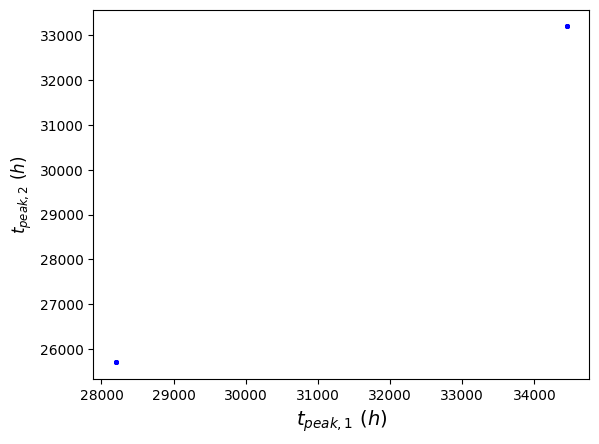

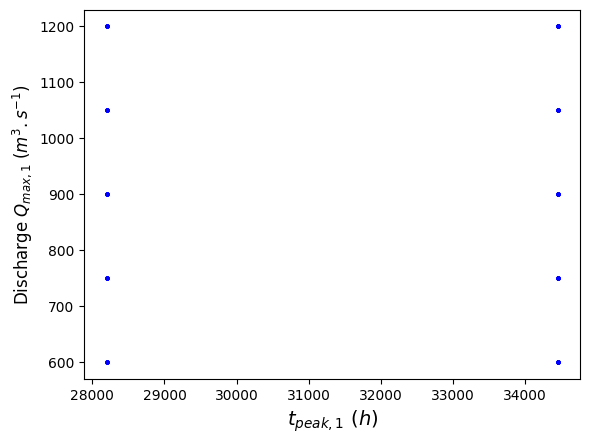

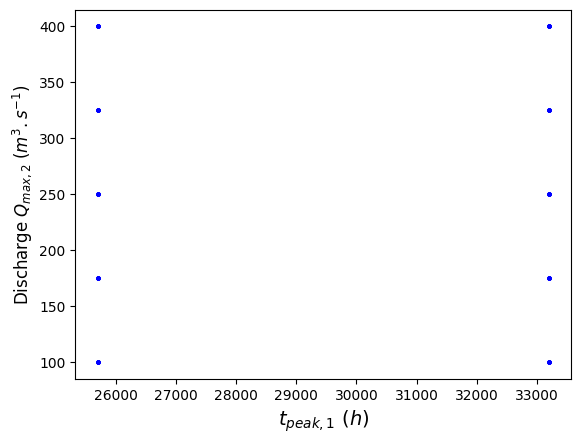

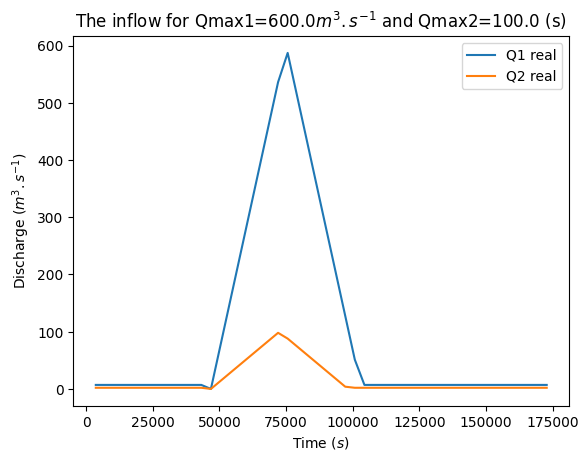

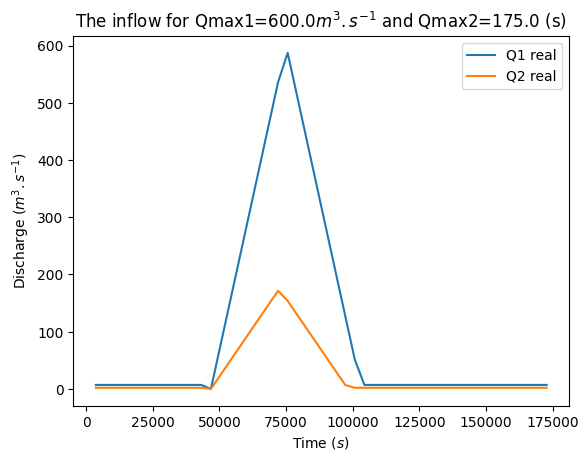

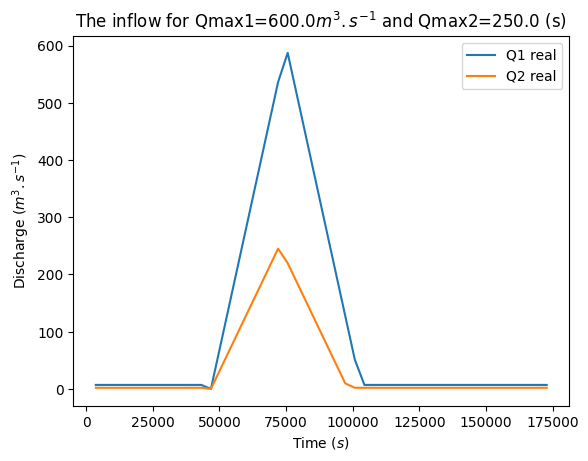

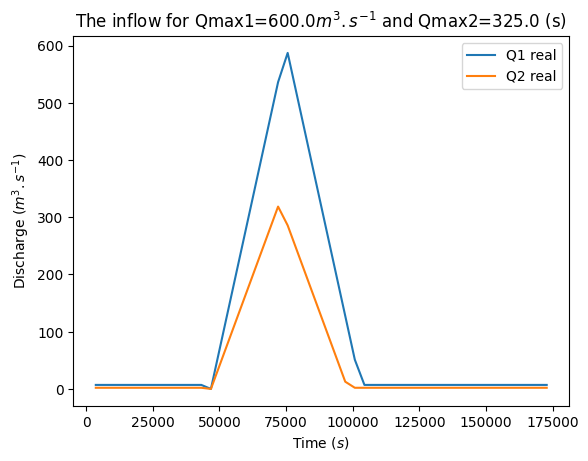

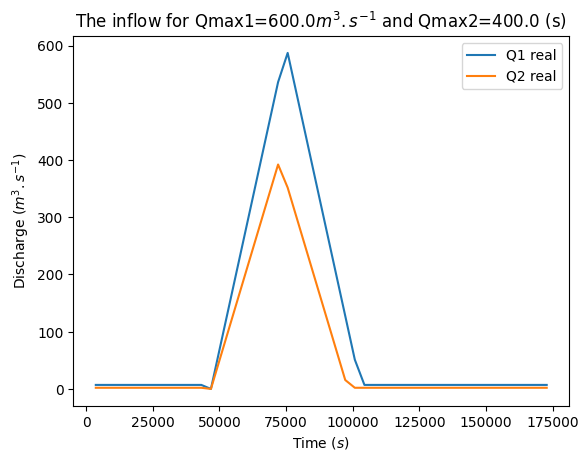

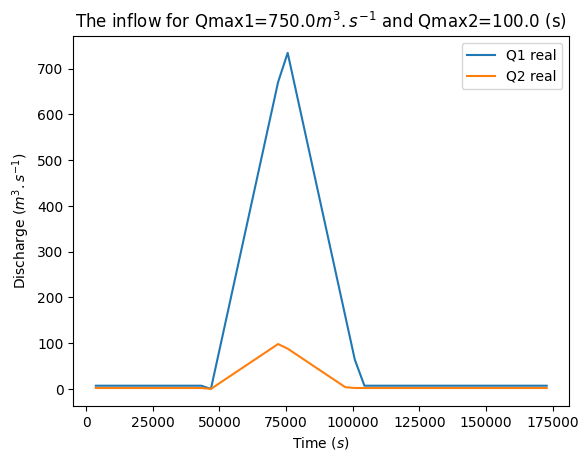

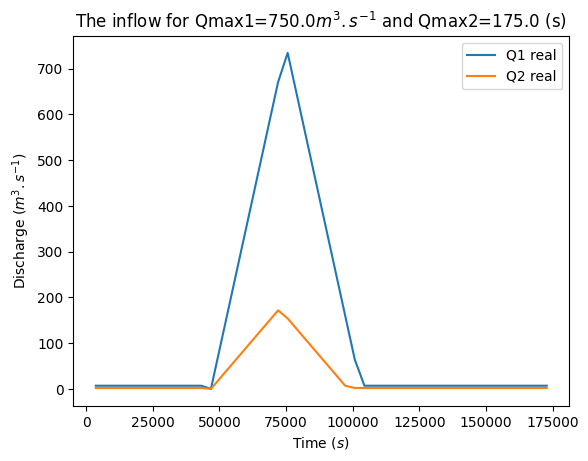

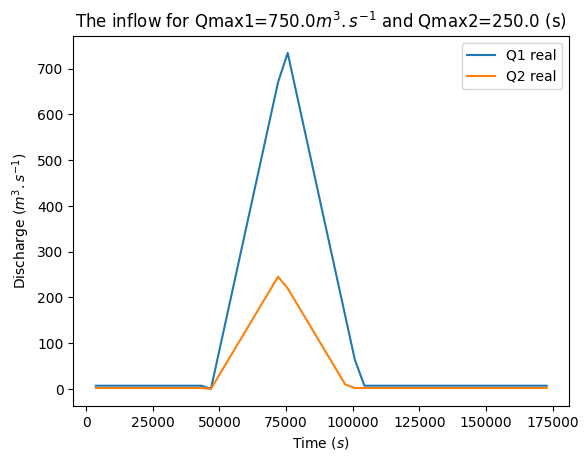

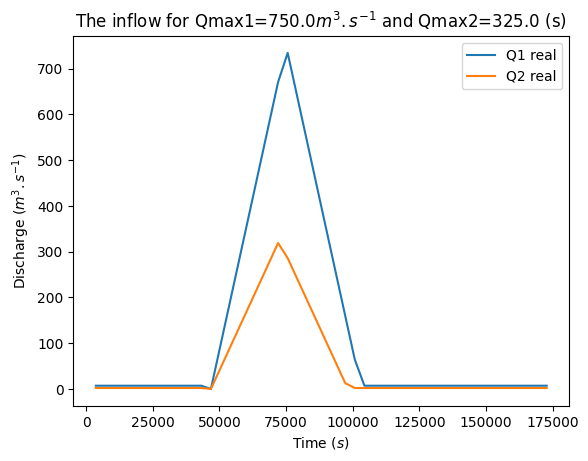

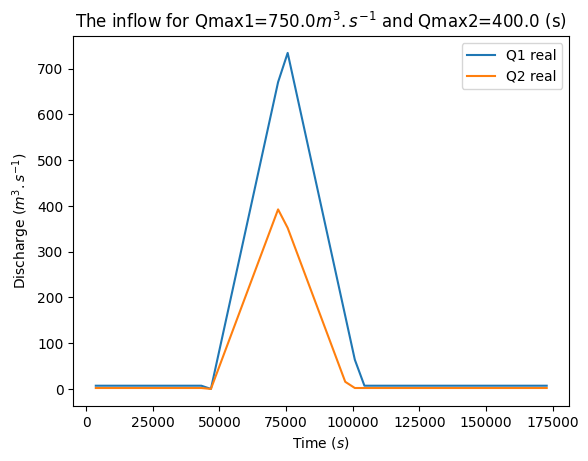

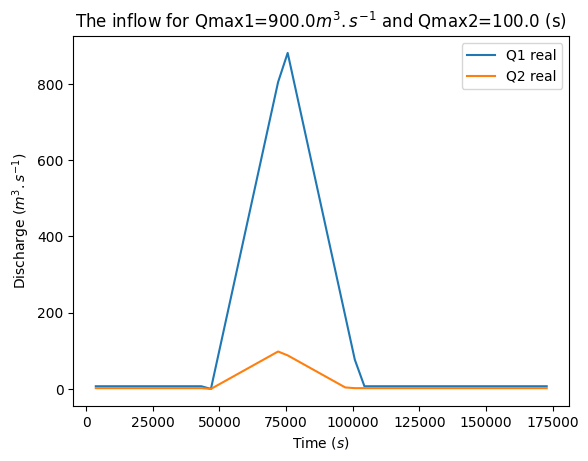

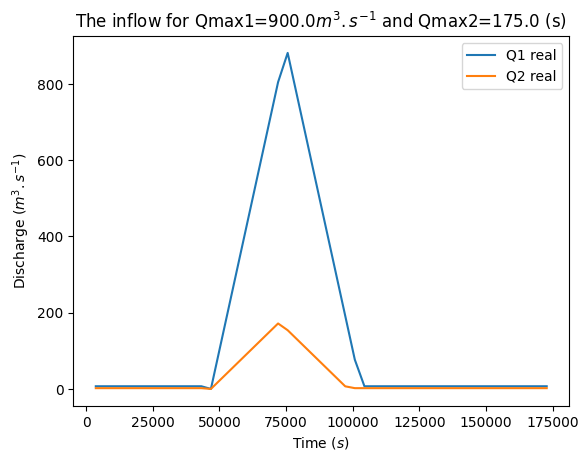

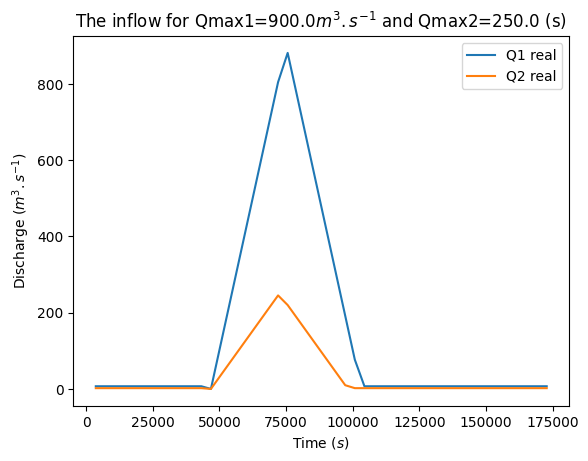

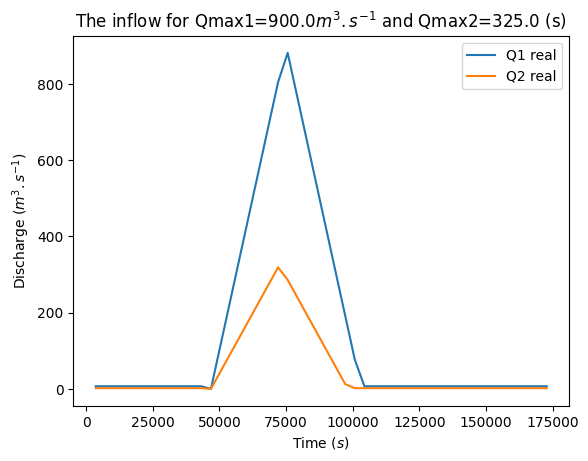

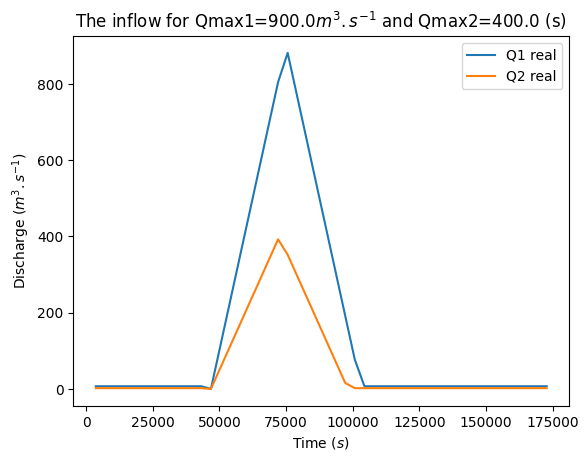

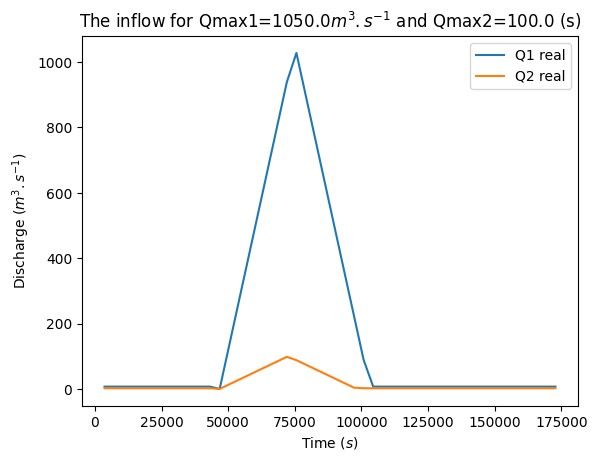

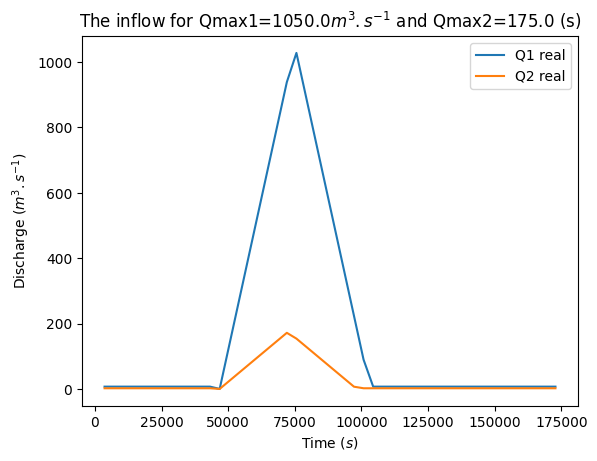

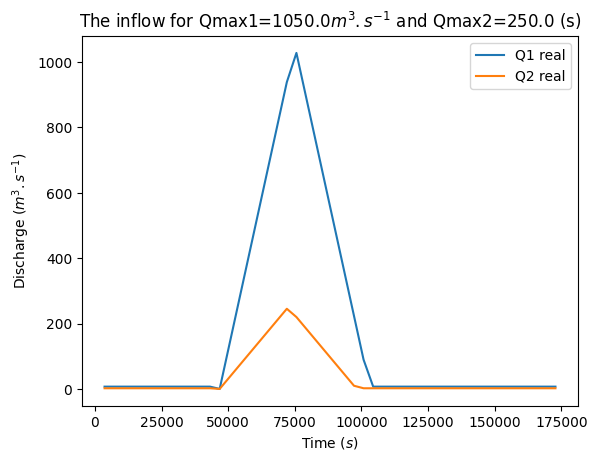

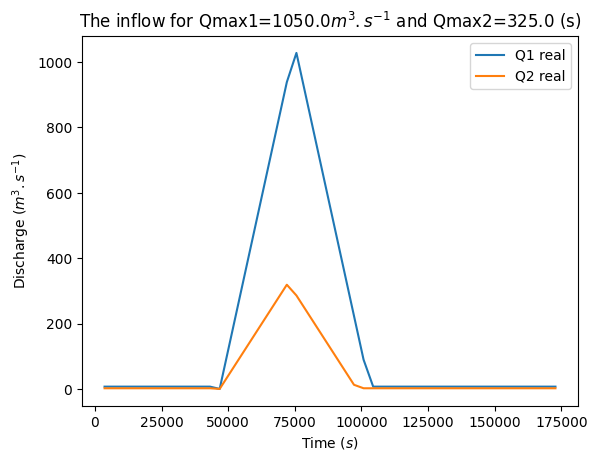

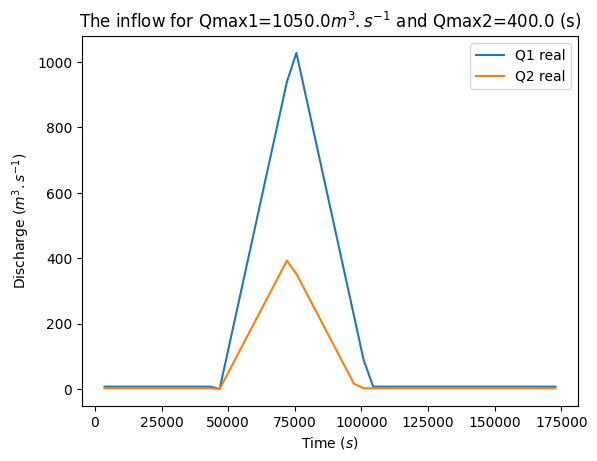

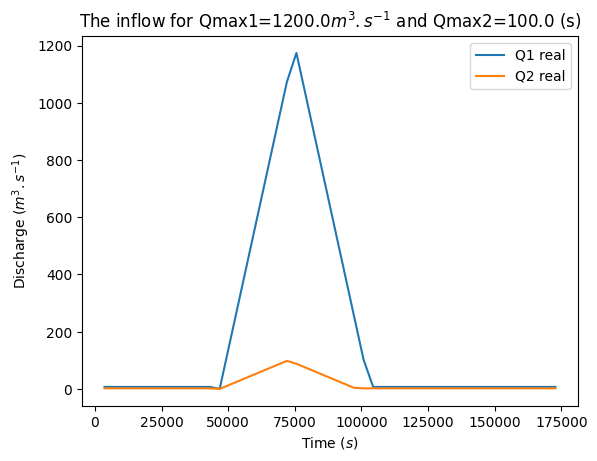

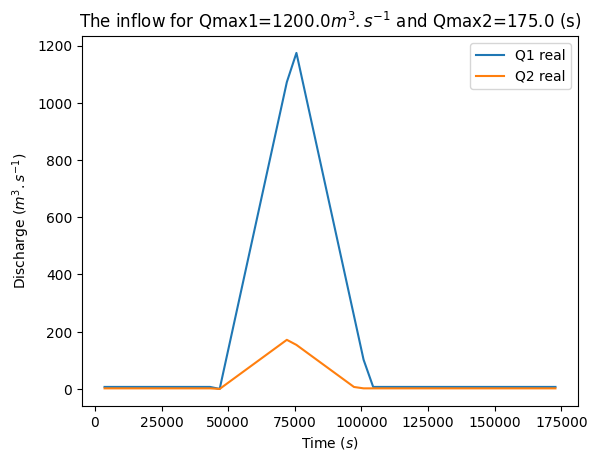

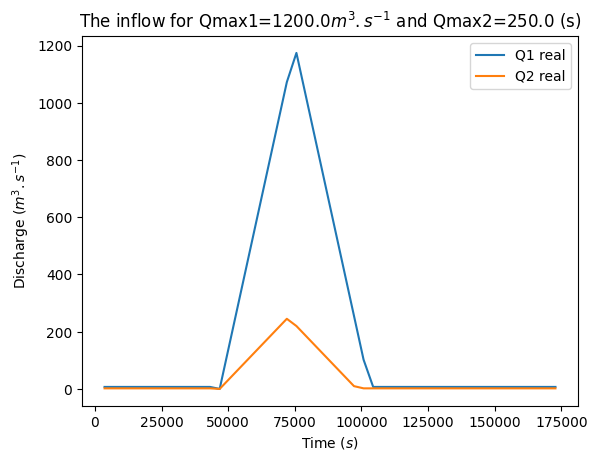

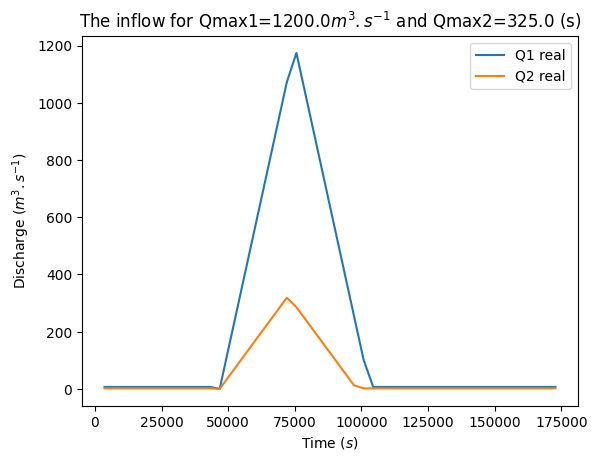

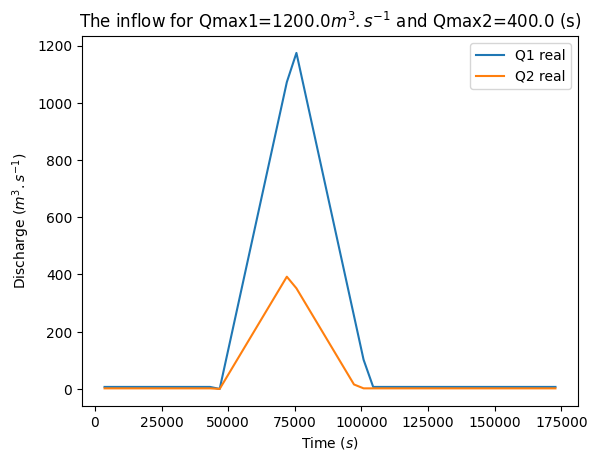

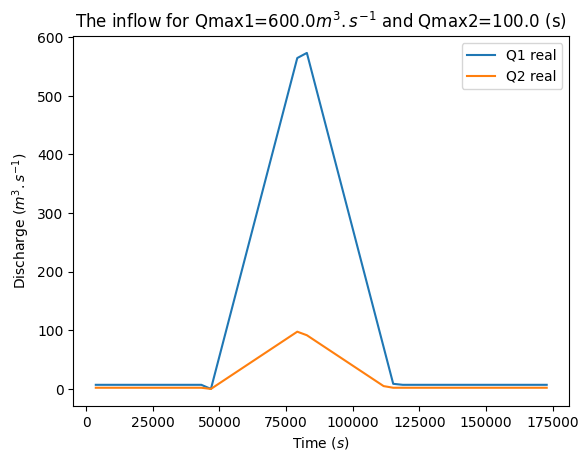

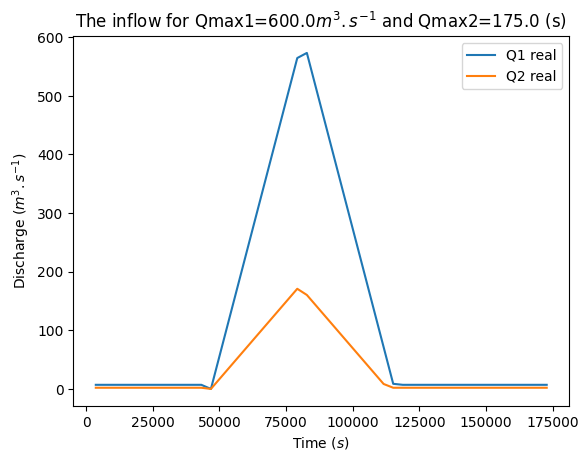

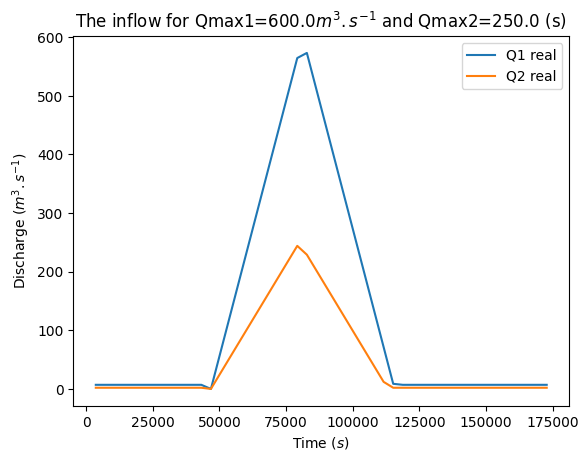

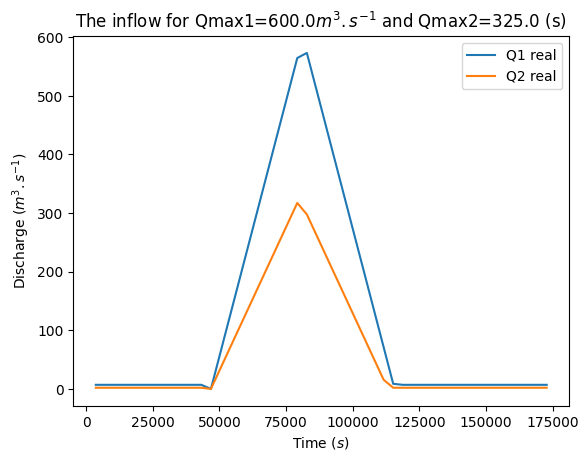

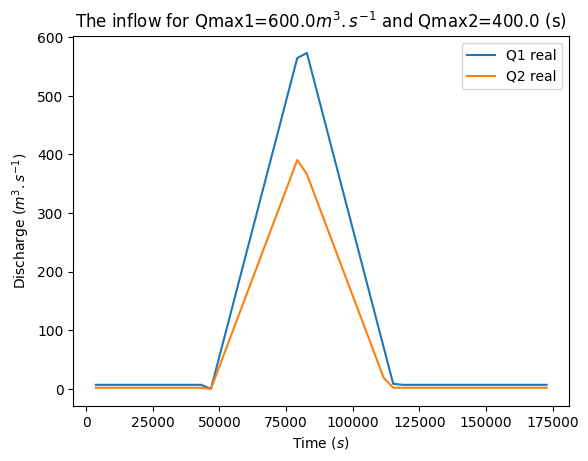

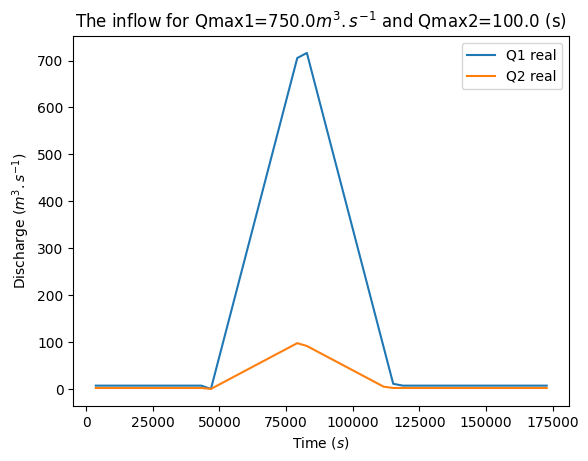

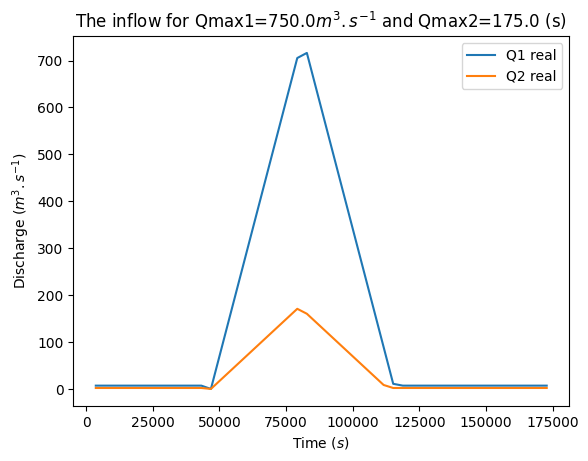

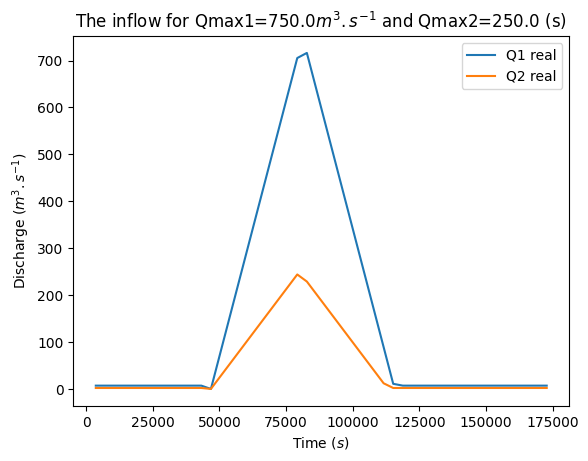

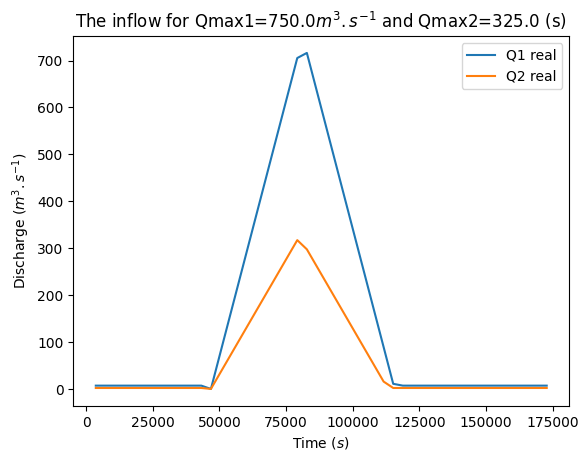

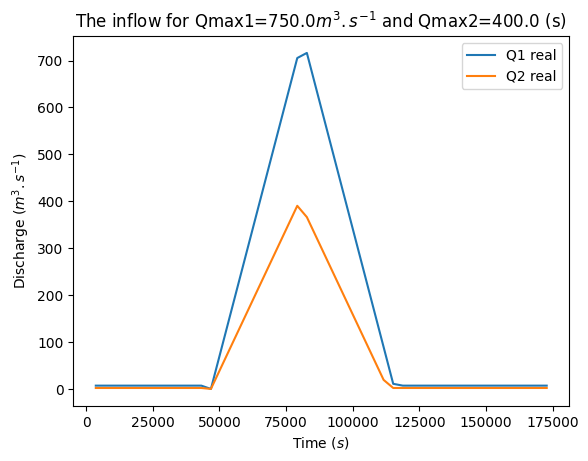

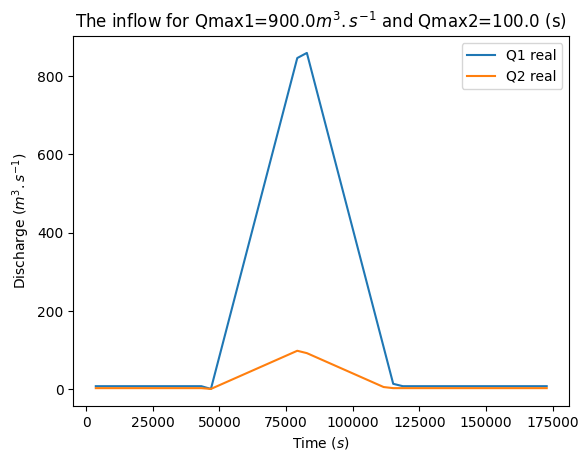

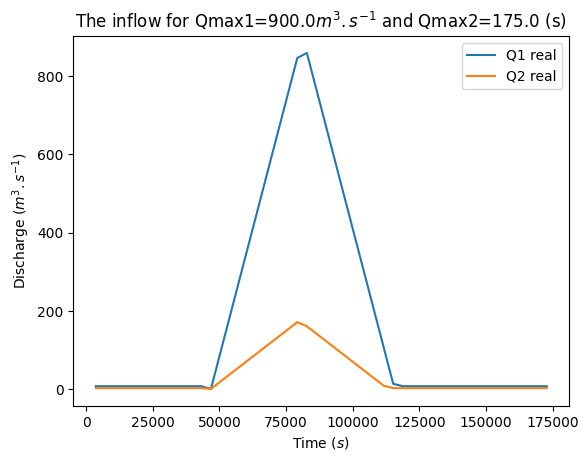

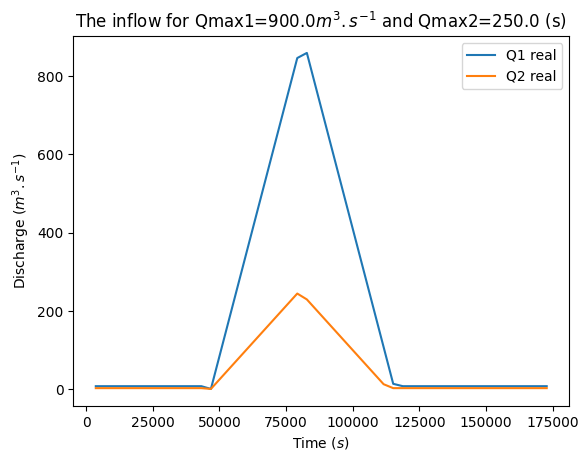

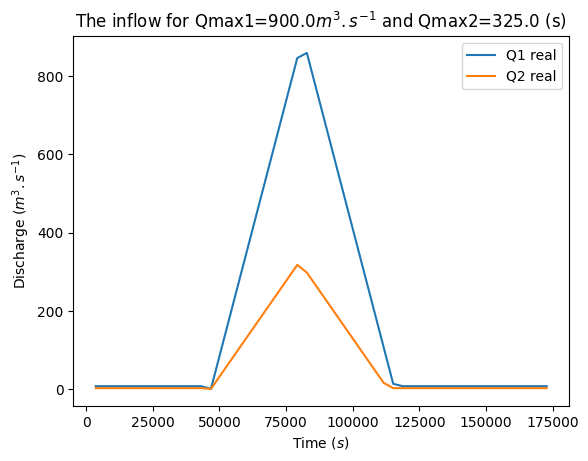

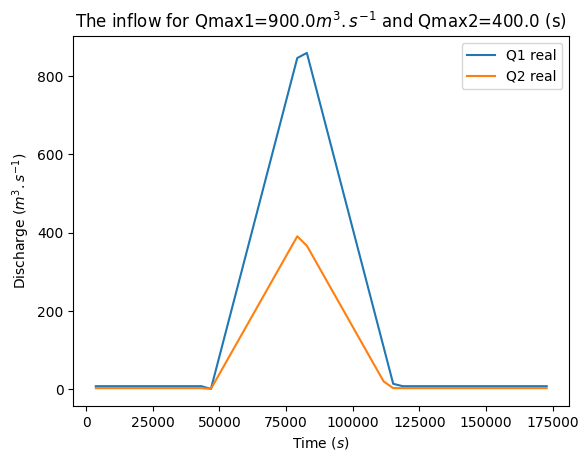

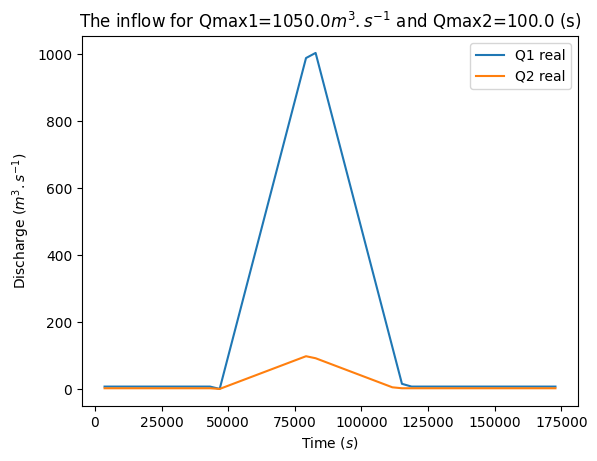

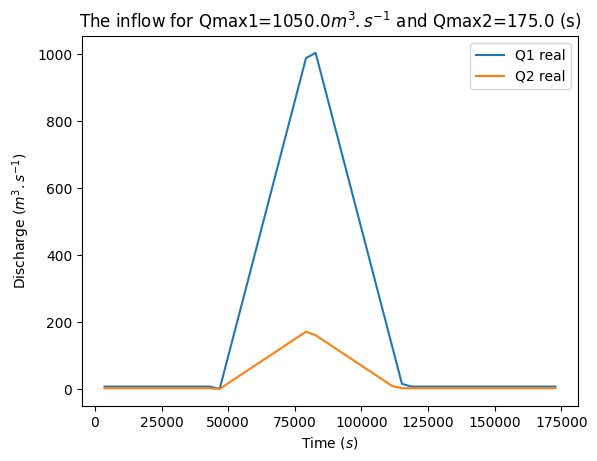

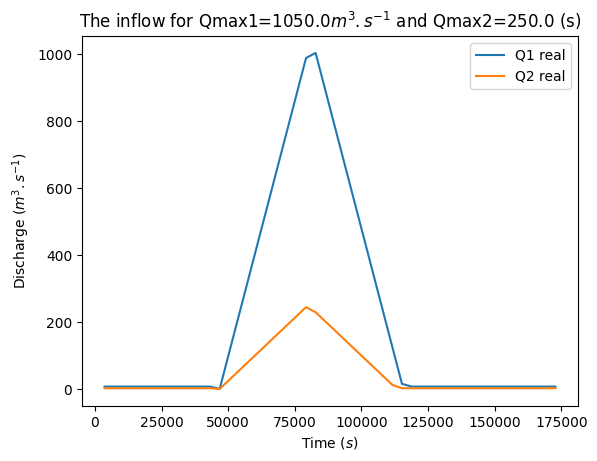

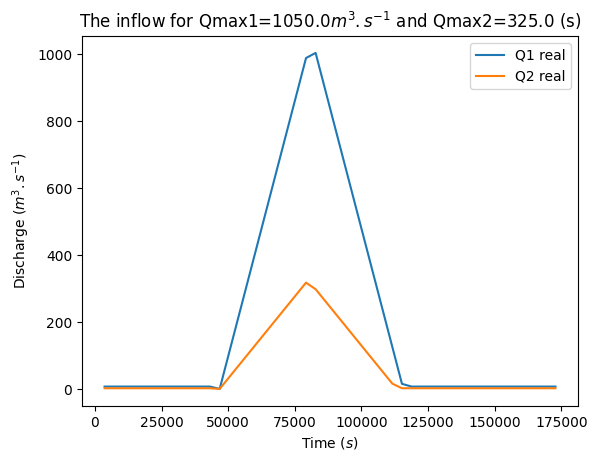

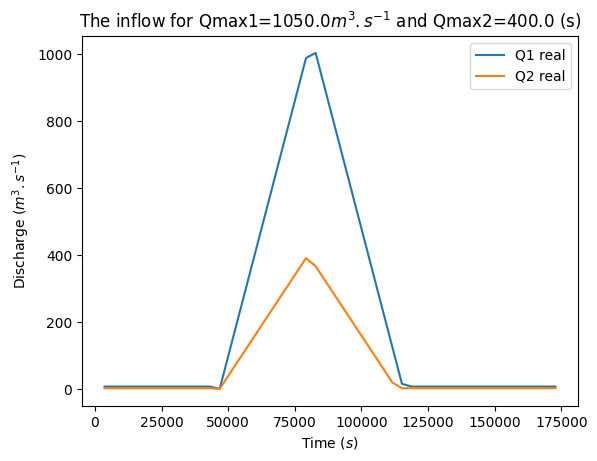

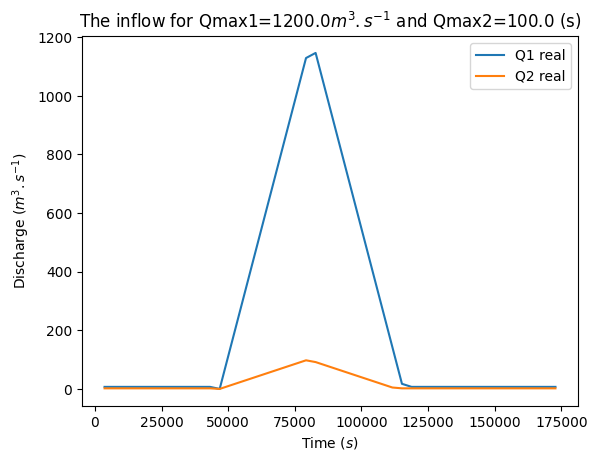

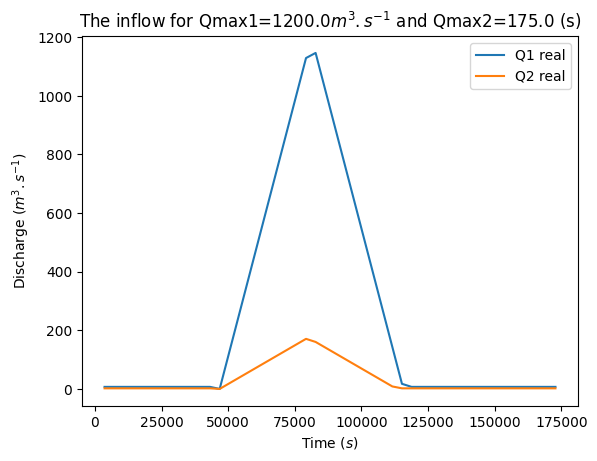

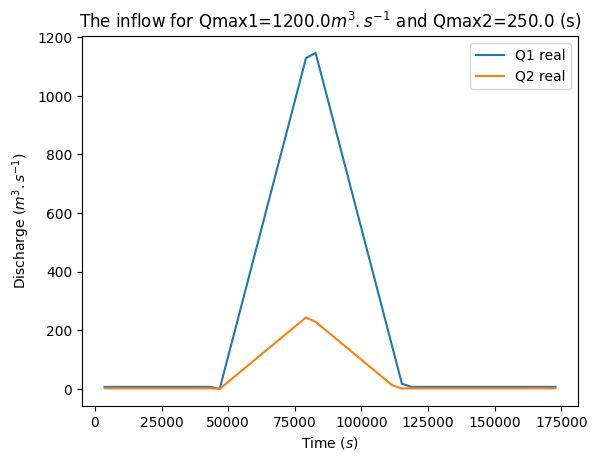

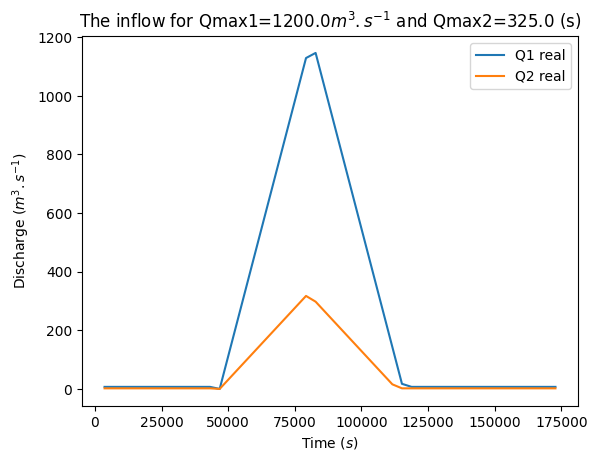

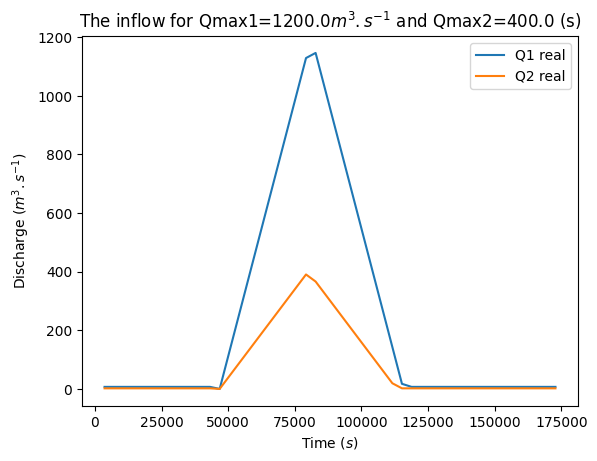

Snapshots shaps is (21801, 269)
cond of C= 4.863766863500525e+18


/home-local/allabou/Bureau/These/Code/test/POD_Basis.py:97: RuntimeWarning: invalid value encountered in sqrt
  Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(self.Snapshots,self.Eigen_vec[:,i])


s_eigen = 1452013.2408419119
Duration: 0:00:03.422191


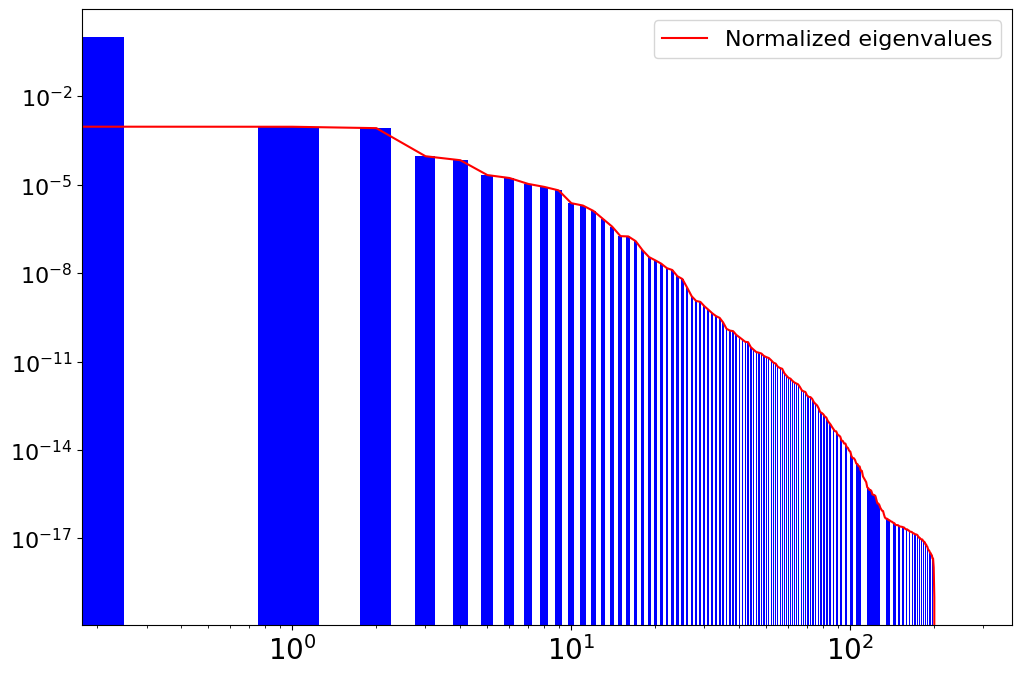

This corresponds to Nrb =  3
Brb shape is (21801, 3)
Nrb is equal to 3
Brb is of shape (21801, 3)
cond of C= 9.092527207891834e+19


/home-local/allabou/Bureau/These/Code/test/POD_Basis_error.py:46: RuntimeWarning: invalid value encountered in sqrt
  Xi[:,i] = (1/(np.sqrt(self.Eigen_val[i])))*np.dot(Snapshots,self.Eigen_vec[:,i])


Duration: 0:00:03.443921
s_eigen = 335.57042581879335


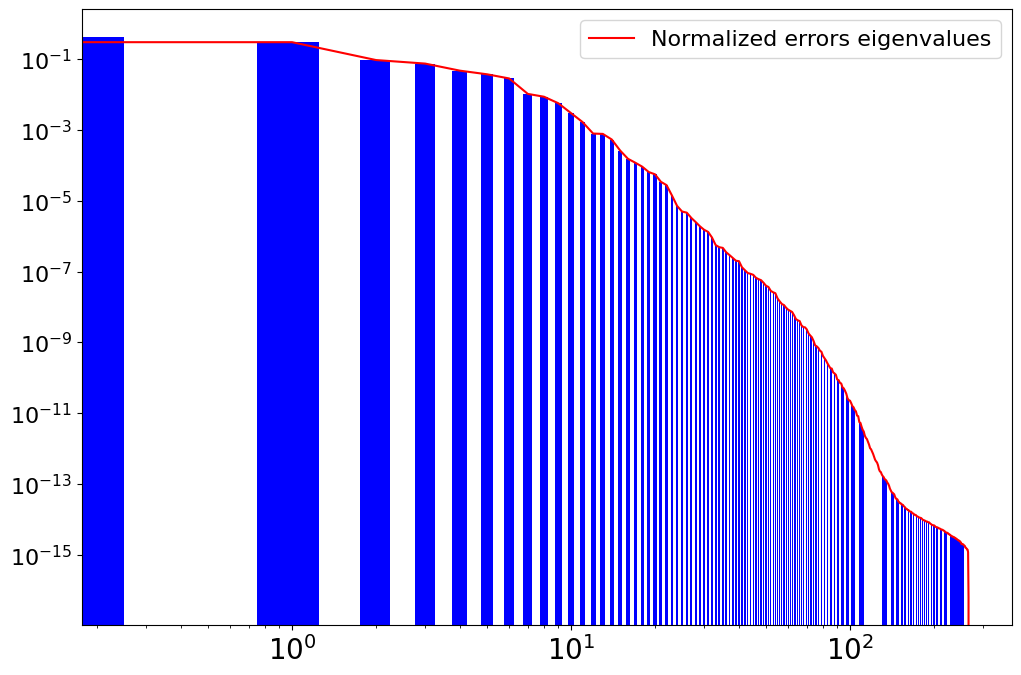

This corresponds to Ner =  10
Ber shape is (21801, 10)
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 20)                120       
                                                                 
 dense_1 (Dense)             (None, 20)                420       
                                                                 
 dense_2 (Dense)             (None, 20)                420       
                                                                 
 dense_3 (Dense)             (None, 20)                420       
                                                                 
 dense_4 (Dense)             (None, 20)                420       
                                                                 
 dense_5 (Dense)             (None, 20)                420       
                                                                 
 

2024-02-15 15:46:36.041082: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-02-15 15:46:36.064512: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-02-15 15:46:36.064635: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Physical devices cannot be modified after being initialized
len Urb_POD_train= (269, 3)
len Urb_POD_train_er= (269, 10)
len P= (269, 5)
len P_train= (188, 5)
len Urb_POD_train= (188, 3)
len Urb_POD_train_er= (188, 10)
len P_val= (54, 5)
len Urb_POD_val= (54, 3)
len Urb_POD_val_er= (54, 10)
len P_test= (27, 5)
len Urb_POD_test= (27, 3)
len Urb_POD_test_er= (27, 10)
Epoch 1/1000


2024-02-15 15:46:37.155545: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-15 15:46:37.374930: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f863d221310 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-02-15 15:46:37.374947: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA RTX A3000 Laptop GPU, Compute Capability 8.6
2024-02-15 15:46:37.378462: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-02-15 15:46:37.388235: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
I0000 00:00:1708008397.442110  206817 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


19/19 [==============================] - 2s 16ms/step - loss: 0.2233 - accuracy: 1.0000 - val_loss: 0.1036 - val_accuracy: 1.0000
Epoch 2/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0302 - accuracy: 1.0000 - val_loss: 0.0043 - val_accuracy: 1.0000
Epoch 3/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0027 - accuracy: 1.0000 - val_loss: 0.0023 - val_accuracy: 1.0000
Epoch 4/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0014 - accuracy: 1.0000 - val_loss: 0.0018 - val_accuracy: 1.0000
Epoch 5/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0012 - accuracy: 1.0000 - val_loss: 0.0018 - val_accuracy: 1.0000
Epoch 6/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0012 - accuracy: 1.0000 - val_loss: 0.0017 - val_accuracy: 1.0000
Epoch 7/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0012 - accuracy: 1.0000 - val_loss: 0.0017 - val_accuracy: 1.0000
Epoch 8/1000
19/19

19/19 [==============================] - 0s 3ms/step - loss: 4.4353e-04 - accuracy: 1.0000 - val_loss: 0.0011 - val_accuracy: 1.0000
Epoch 113/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6682e-04 - accuracy: 1.0000 - val_loss: 0.0011 - val_accuracy: 1.0000
Epoch 114/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.4265e-04 - accuracy: 1.0000 - val_loss: 0.0013 - val_accuracy: 1.0000
Epoch 115/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.3643e-04 - accuracy: 1.0000 - val_loss: 0.0010 - val_accuracy: 1.0000
Epoch 116/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.2917e-04 - accuracy: 1.0000 - val_loss: 0.0012 - val_accuracy: 1.0000
Epoch 117/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.1840e-04 - accuracy: 1.0000 - val_loss: 9.3205e-04 - val_accuracy: 1.0000
Epoch 118/1000
19/19 [==============================] - 0s 3ms/step - loss: 4.6860e-04 - accuracy: 1.0000 - val_loss: 0.001

... (15 outputs left out)

19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2872 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 605/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3351 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 606/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.2979 - val_loss: 0.0024 - val_accuracy: 0.0000e+00
Epoch 607/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3404 - val_loss: 0.0026 - val_accuracy: 0.3333
Epoch 608/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 609/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2340 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 610/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.2660 - val_loss: 0.0025 - val_accuracy: 0.

19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3351 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 717/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2713 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 718/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 719/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3032 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 720/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3351 - val_loss: 0.0026 - val_accuracy: 0.3333
Epoch 721/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.1649 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 722/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3032 - val_loss: 0.0025 - val_accuracy: 0.

Epoch 829/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3351 - val_loss: 0.0027 - val_accuracy: 0.3333
Epoch 830/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.3245 - val_loss: 0.0026 - val_accuracy: 0.0000e+00
Epoch 831/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.2766 - val_loss: 0.0025 - val_accuracy: 0.0000e+00
Epoch 832/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3245 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 833/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3351 - val_loss: 0.0027 - val_accuracy: 0.0370
Epoch 834/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0024 - val_accuracy: 0.0000e+00
Epoch 835/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3138 - val_loss: 0.0026 - v

19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3032 - val_loss: 0.0026 - val_accuracy: 0.3333
Epoch 942/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.3032 - val_loss: 0.0029 - val_accuracy: 0.0370
Epoch 943/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.1383 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 944/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.2872 - val_loss: 0.0027 - val_accuracy: 0.0000e+00
Epoch 945/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0025 - val_accuracy: 0.3333
Epoch 946/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0070 - accuracy: 0.3191 - val_loss: 0.0025 - val_accuracy: 0.0370
Epoch 947/1000
19/19 [==============================] - 0s 3ms/step - loss: 0.0071 - accuracy: 0.2394 - val_loss: 0.0026 - val_accuracy: 0.3333
Epo

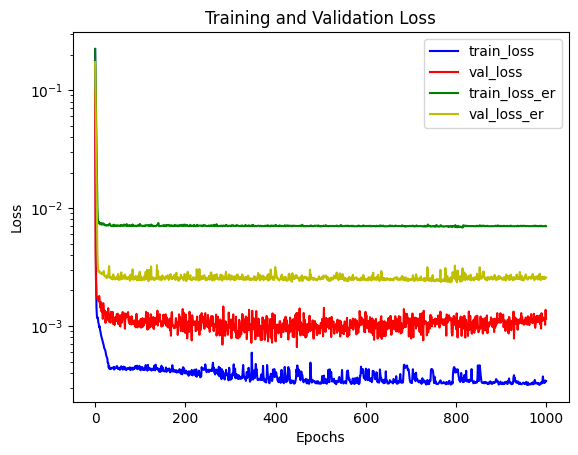

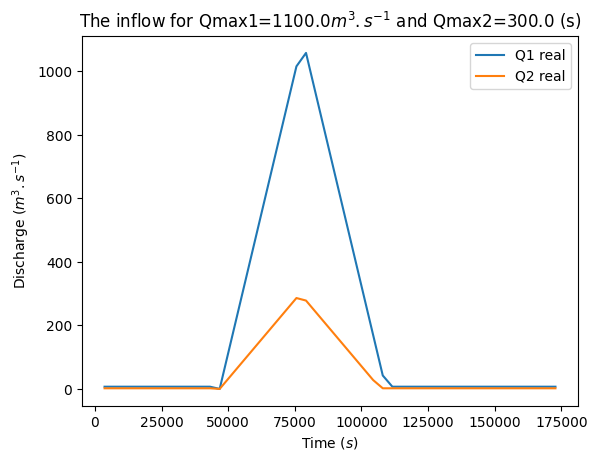

Number of elements in Time: 48
Number of elements in Flow1: 48
1/1 [==============================] - 0s 20ms/step
Uh_POD_NN shape (1, 21801)
(48,)
/home-local/allabou/Bureau/These/Code/test
Printing case files 
 from /home-local/allabou/Bureau/dasshydro-main/cases/dev_case/Aude/built_bin  
  to  /home-local/allabou/Bureau/dasshydro-main/code/bin_A 
rm -rf ./bin_A/res/*
rm -rf ./bin_A/graph/*
rm -rf ./bin_A/min/*
clean= True
{'mesh_name': 'final_mesh.geo', 'ts': 216000.0, 'dta': 0, 'dtw': 10800.0, 'dtp': 60.0, 'dt': 0.1, 'temp_scheme': 'euler', 'spatial_scheme': 'first_b1', 'adapt_dt': 1, 'cfl': 0.5, 'feedback_inflow': 1, 'coef_feedback': 0.1, 'heps': 0, 'friction': 1, 'g': 10.0, 'w_tecplot': 0, 'w_vtk': 0, 'w_gnuplot': 1, 'w_obs': 0, 'use_obs': 0, 'max_nt_for_adjoint': 100000000, 'c_manning': 0, 'c_manning_beta': 0, 'c_bathy': 0, 'c_hydrograph': 1, 'c_ratcurve': 0, 'c_rain': 0, 'c_ic': 0, 'restart_min': 0, 'eps_min': 0}
call dassflow2d.wrapping.m_mesh.msh()
call         dassflow2d.wra

(21801, 9)


2024-02-15 15:50:31.021 ( 250.318s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


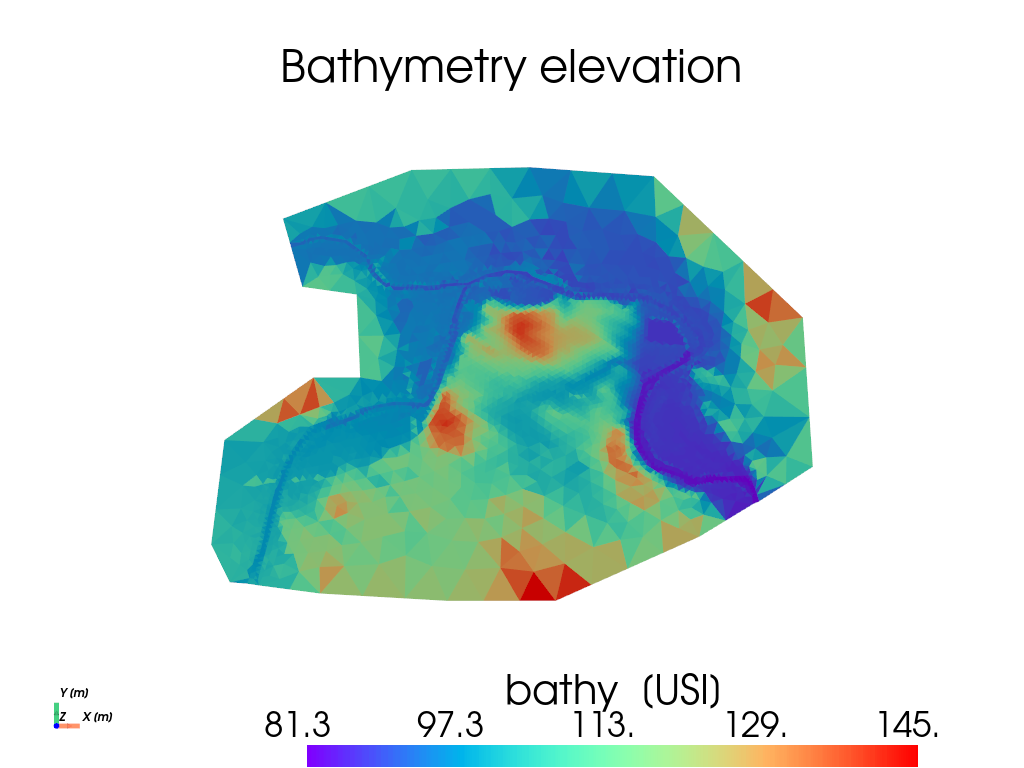

2024-02-15 15:50:31.214 ( 250.510s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


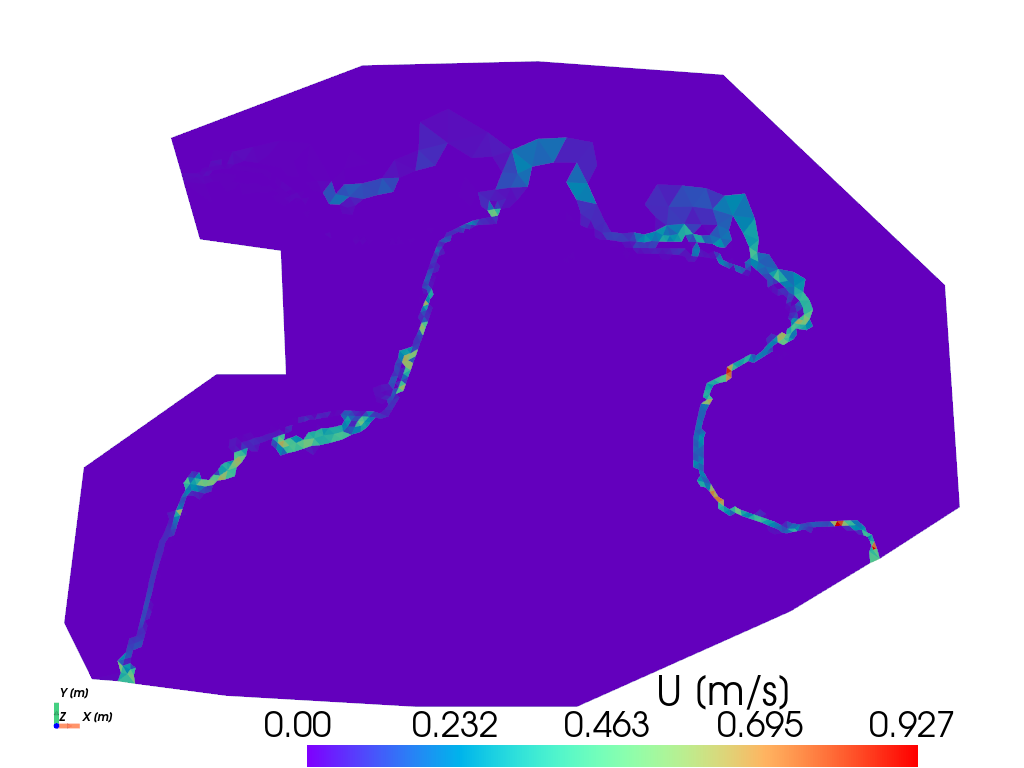

2024-02-15 15:50:31.307 ( 250.604s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


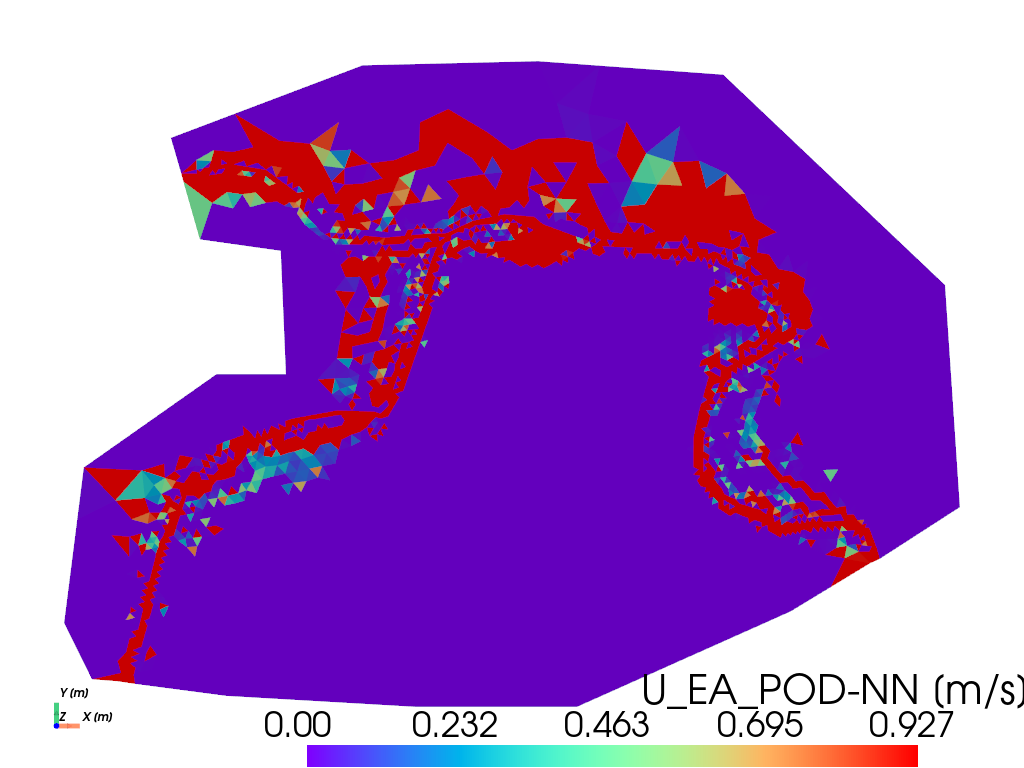

2024-02-15 15:50:31.409 ( 250.706s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


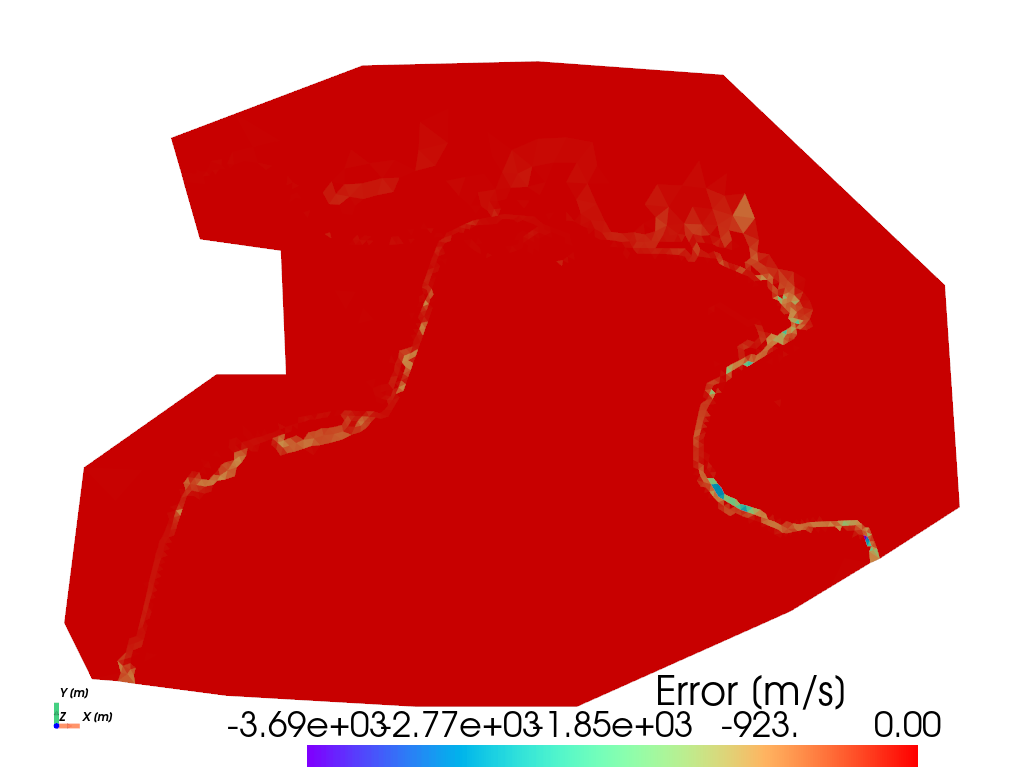

2024-02-15 15:50:31.507 ( 250.803s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


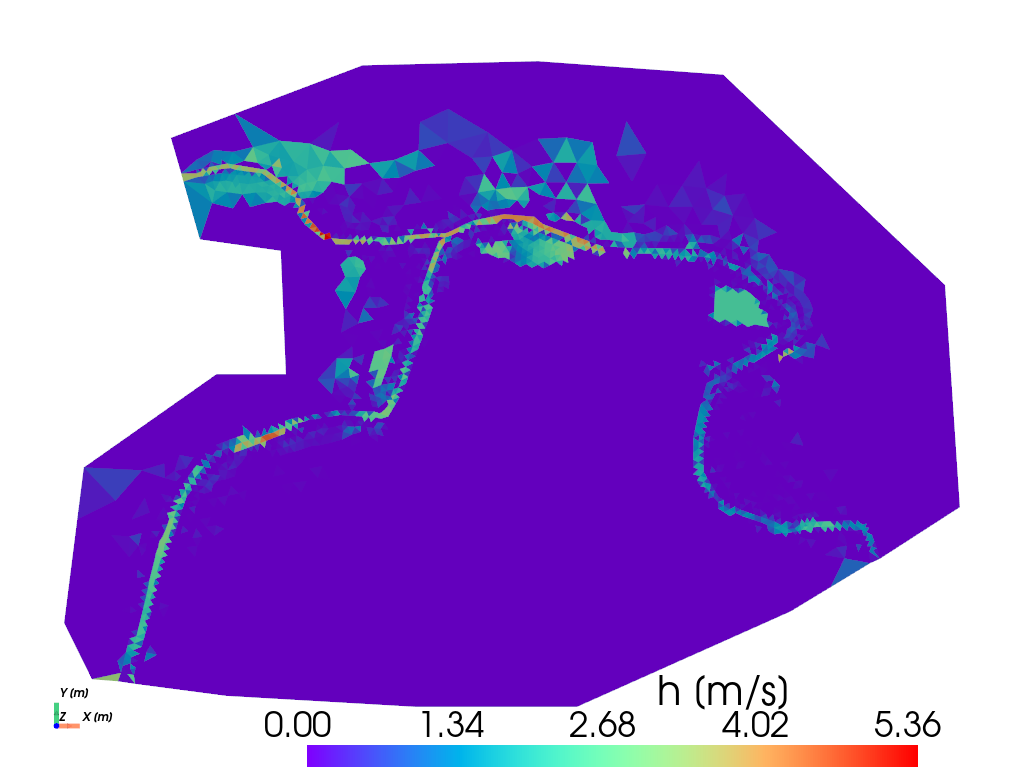

2024-02-15 15:50:31.609 ( 250.906s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


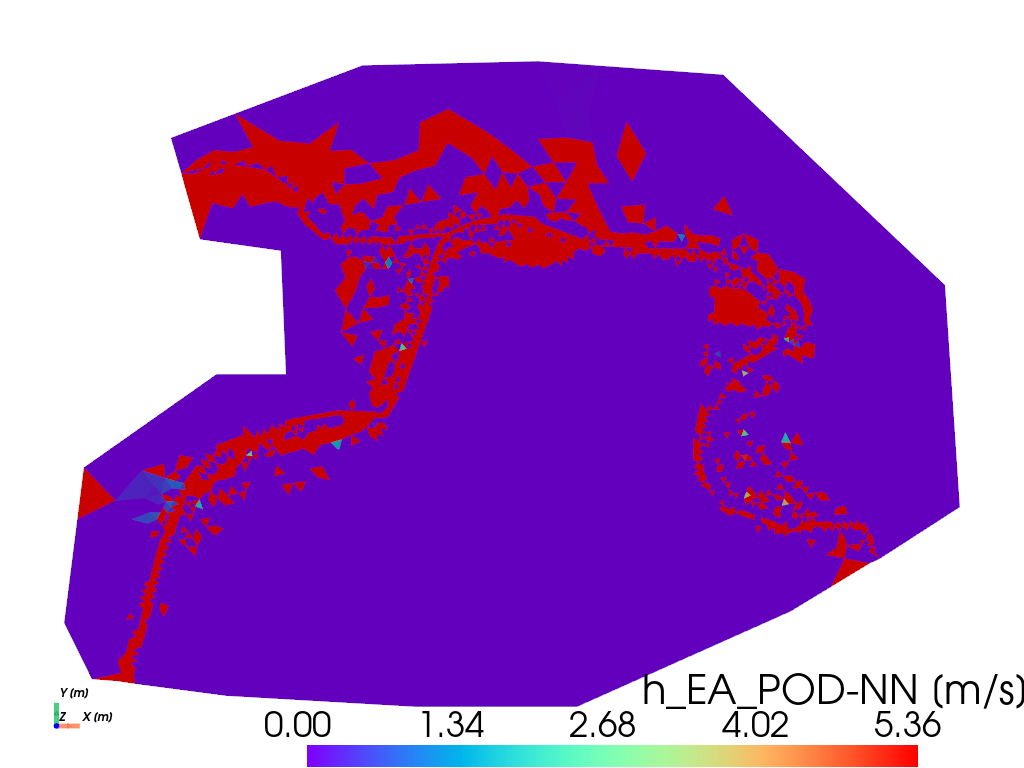

2024-02-15 15:50:31.707 ( 251.004s) [    7F882B022280]       vtkAxesActor.cxx:412   WARN| One or more normalized shaft lengths       are < 0 or > 1 and may produce unexpected results.
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/pyvista/jupyter/notebook.py:34: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


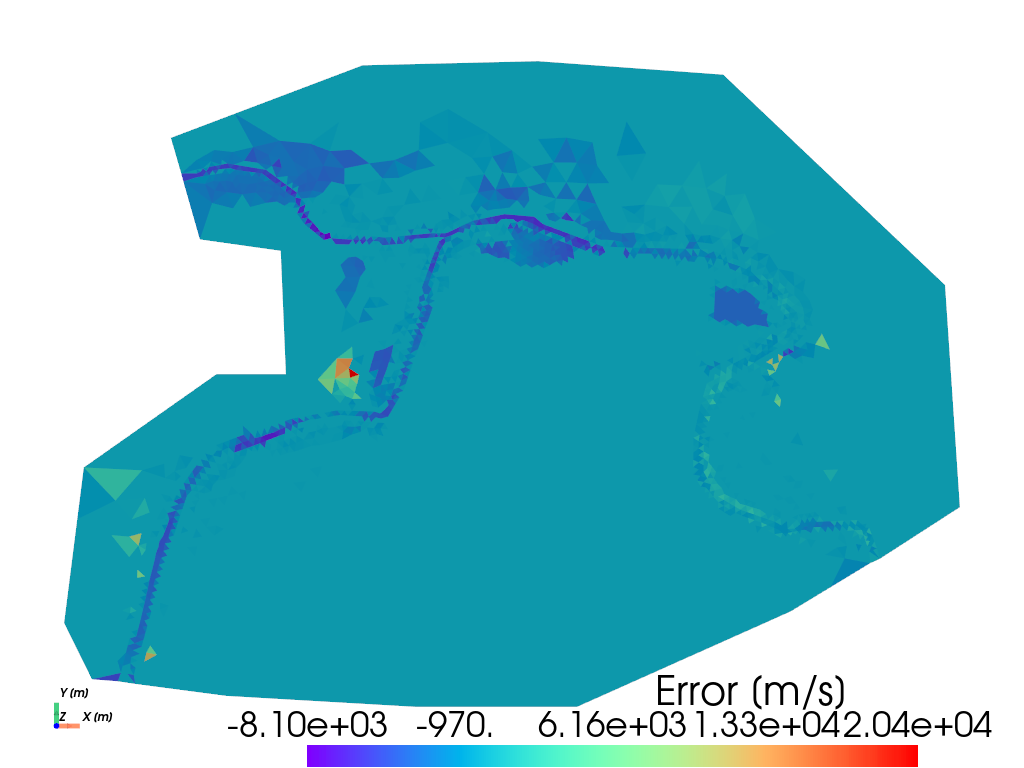

/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home-local/allabou/anaconda3/envs/tensorflow/lib/python3.9/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret 

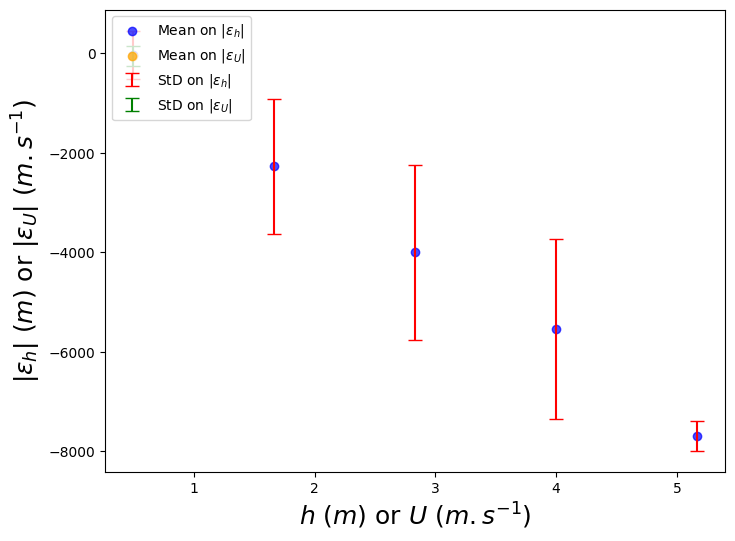

data_h= (7267,)
mu_h= 492.4654704824411
std_h= 1239.2127556484845
cdf_h= [0.34553557 0.34553557 0.91551729 ... 0.99989847 0.41281422 0.75067692]
data_u= (7267,)
mu_u= 48.68381231297984
std_u= 195.85414950595126
cdf_u= [0.40184602 0.40184602 0.41854016 ... 0.45191576 0.99410111 0.99974785]


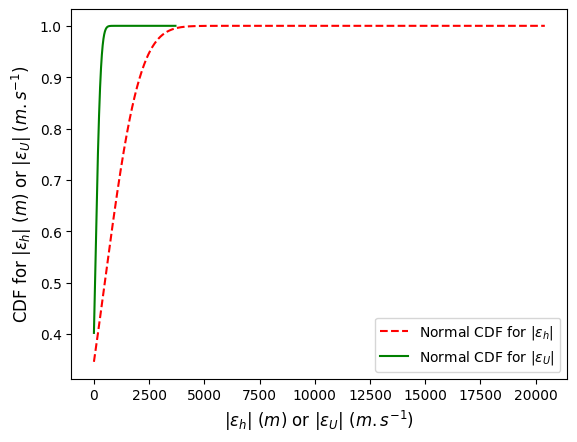

madiane of h is 5.0190374293614805e-05
madiane of u is 7.826325789067183e-06


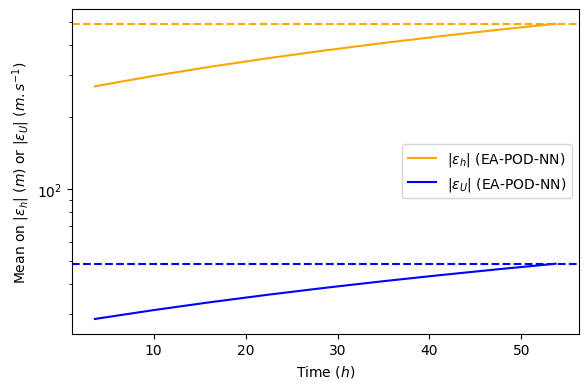

In [17]:
if __name__ == "__main__":
   
    ###########################################################################
    # Parameter space construction
    ###########################################################################
    
    # Construct the parameter space using HydrographGenerator
    hydrograph_generator = HydrographGenerator()
    
    # Check the parameter constraint (phase-shofted with 3.5%)
    hydrograph_generator.check_constraint(*hydrograph_params['constraint_values'])
    
    # Construct the parameter space
    parameter_space = hydrograph_generator.generate_parameter_space(
        hydrograph_params['mu1_range'],
        hydrograph_params['mu2_range'],
        hydrograph_params['mu3_range'],
        hydrograph_params['mu4_range'],
        hydrograph_params['constraint_values'][1]
    )
    echantillons = np.array(parameter_space)
    
    # Plot the parameter space
    hydrograph_generator.plot_parameter_space(
        echantillons,
        hydrograph_params['param'],
        hydrograph_params['tmontee1'],
        hydrograph_params['tmontee2']
    )

    # Define the hydrographs numpy vectors
    Qin1, Qin2 = hydrograph_generator.generate_hydrographs(echantillons, hydrograph_params['tmontee1'], hydrograph_params['tmontee2'])
   
    # Update the dictionary with the desired values
    dassflow_params['Qin1'] = Qin1
    dassflow_params['Qin1'] = Qin2
    
    # Construct the parameter set for the EA-POD-NN method
    POD_NN_Parameters = hydrograph_generator.generate_pod_nn_parameters(echantillons, hydrograph_params['tmontee1'], hydrograph_params['tmontee2'])

    # Update the dictionary with the desired values
    my_nn_params['input_dim'] = len(POD_NN_Parameters[0])
    
    # ##########################################################################
    # # Snapshots computation
    # ##########################################################################
    
    # # Configure the logging system to output log messages with a severity level of DEBUG
    # logging.basicConfig(level=logging.DEBUG)
    # print(os.path.abspath("."))
    
    # # Define the DassFlow class with corresponding paths
    # dassflow_runner = DassFlowRunner(
    #     dassflow_params['dassflow_dir'],
    #     dassflow_params['code_dir'],
    #     dassflow_params['save_dir']
    # )
    
    # # Copy the case files
    # dassflow_runner.copy_case_files(os.path.join(dassflow_params['code_dir'], "bin_A"))
    
    # # Initialize the model
    # dassflow_runner.initialize_model(os.path.join(dassflow_params['code_dir'], "bin_A"))
    
    # # Set the hydrographs vectors
    # dassflow_runner.set_qin_data(dassflow_params['Qin1'], dassflow_params['Qin2'])
    
    # # Run the DassFlow simulation in parallel
    # dassflow_runner.run_simulations(16, dassflow_params['run_type'], dassflow_params['ts'], dassflow_params['dtw'])
   
    ###########################################################################
    # Reduced basis Brb and Reduced basis Ber computation
    ###########################################################################
    
    # Compute the RB matrix Brb
    
    # Initialize the POD processor
    pod_processor = PODProcessor(**pod_params)
    
    # Read the hdf5 files and construct the snapshots matrix
    Snapshots = pod_processor.read_data_files()
    print('Snapshots shaps is',Snapshots.shape)
    
    # Comute the eigen values of the correlation matrix C
    pod_processor.compute_eigenvalues()
    
    # Compute and plot the eigenvalues and eigenvectors of C
    pod_processor.plot_eigenvalues()
    
    # Truncate the first Nrb modes
    Nrb = pod_processor.compute_number_of_modes(pod_params['epsilon_POD'])
    # Update the dictionary with the desired values
    my_nn_params['Nrb'] = Nrb
        
    
    # Verify the error estimtion of POD method
    # pod_processor.compute_error_estimation()  # Uncomment this line if needed
    
    # Get the RB matrix
    Brb = pod_processor.truncate_reduced_basis(Nrb)
    
    # Compute the RB matrix Ber
    
    # Initialize the POD  error processor
    pod_processor_er = PODProcessor_error(**pod_params_er)
    
    # Comute the eigen values of the correlation matrix C
    pod_processor_er.compute_eigenvalues_er(Snapshots,Nrb,Brb)
    
    # Compute and plot the eigenvalues and eigenvectors of C
    pod_processor_er.plot_eigenvalues_er() 
    
    # Truncate the first Nrb modes
    Ner = pod_processor_er.compute_number_of_modes_er(pod_params_er['epsilon_er'])

    # Update the dictionary with the desired values
    my_nn_params['Ner'] = Ner
    my_nn_params['Neurons_er'] = 2 * Ner
    
    # Get the RB matrix
    Ber = pod_processor_er.truncate_reduced_basis_er(Ner)
   
    ###########################################################################
    # EA-POD-NN method: offline phase 
    ###########################################################################
    
    # Initialize the NN parameters
    my_nn = POD_NN_METHOD(**my_nn_params)
    
    # Load the data
    my_nn.load_data()
    
    # Normalize the data
    my_nn.Urb_POD,Urb_POD_max,Urb_POD_min = my_nn.normalize_data(my_nn.Urb_POD)
    my_nn.Urb_POD_er,Urb_POD_er_max,Urb_POD_er_min = my_nn.normalize_data(my_nn.Urb_POD_er)
    my_nn.P,P_max,P_min = my_nn.normalize_data(my_nn.P)
    
    # Split data into train, test and validation parts
    my_nn.split_data()
    
    # Train the NN 
    history,history_er = my_nn.train_models()
    #history_er = my_nn.train_model_er()
    
    # Evaluate the NN model on the validation data
    my_nn.evaluate_model()
    
    # Plot the loss function of the NN 
    my_nn.plot_loss(history,history_er)
    
    # Save the optimized NN parameters
    my_nn.save_model('Neural-network-1','Neural-network-2')
   
    ###########################################################################
    # EA-POD-NN method: online phase
    ###########################################################################
    
    # Computation of the hydrographs to simulate the reference solution
    hydrograph_generator.generate_hydrograph_online(np.zeros(hydrograph_params['n']), np.zeros(hydrograph_params['n']),
                                                    hydrograph_generator.Time, hydrograph_params['tmontee1'], hydrograph_params['param'])
    

    # Instantiate the class with required parameters
    pod_nn_prediction = POD_NN_PREDICTION(my_nn.model,my_nn.model_er, Brb, Ber, P_max,P_min,
                                          Urb_POD_max,Urb_POD_min,Urb_POD_er_max,Urb_POD_er_min)

    # Use the method to predict solution
    h_POD_NN, norm_vel_POD_NN = pod_nn_prediction.predict_solution(my_nn, hydrograph_params['param'],
                                                                   hydrograph_generator.Time_simu,len(Brb))
    
    
    ###########################################################################
    # Compute the reference solution for the online phase
    ###########################################################################
    
    # Initialise the simulation
    simulation = DassflowSimulation()
    
    # Load the inflows vectors
    simulation.load_inflow('Q_1.npy', 'Q_2.npy')
    
    # Setup the directories for the simulation
    simulation.setup_directories("/home-local/allabou/Bureau/dasshydro-main")
    
    # Initialize the dassFlow model
    simulation.initialize_model()
    
    # Get the boundary conditions
    simulation.get_boundary_conditions()
    
    # Run the simulation
    simulation.run_simulation()
    
    # Get the model outputs: h the water depth and nor_vel the velocity norm
    h, norm_vel = simulation.get_output('/home-local/allabou/Bureau/These/Code/Code_reduction/Dassflow_sol.npy')
    
    # Plot the bathymetry
    simulation.plot_bathy()
    
    # Compute the absoolute error between the reference solution and EA-POD-NN one
    Vel_error = simulation.error_computation(norm_vel, norm_vel_POD_NN)
    h_error = simulation.error_computation(h, h_POD_NN)
    
    # Plot the velocity norm outputs
    simulation.plot_velocity_outputs(norm_vel[:, -1], norm_vel_POD_NN[:, -1], Vel_error[:, -1])
    
    # Plot the water depth outputs
    simulation.plot_water_depth_outputs(h[:, -1], h_POD_NN[:, -1], h_error[:, -1])
    
    # Plot the histograme of the error on the water depth and velocity norm
    simulation.plot_error_histogram(h[:, -1], h_error[:, -1], norm_vel[:, -1], Vel_error[:, -1], np.linspace(0, 7, 7), np.linspace(0, 7, 6))

    # Compute and plot the Cummulative Distribution Function (CDF)
    simulation.plot_cdf(h_error[:, -1], Vel_error[:, -1])
    
    # Compute the means error in function of time
    simulation.plot_mean_errors(h_error, Vel_error)
    